# 🧮 La neurona desde el álgebra lineal

*Creado: 2026-11-27 · Unidad 1 · Semana 1 · Material de profundización*

> 🎯 **Objetivo.** Entender **qué es matemáticamente una neurona**, viéndola con los ojos del álgebra lineal: en qué espacio viven sus entradas, qué transformación hace, qué "ve" y qué no "ve", y por qué su frontera de decisión es un hiperplano. Al final construirás una neurona y la **entrenarás solo con álgebra lineal**, proyectando un vector sobre un subespacio, sin descenso de gradiente.

## 📖 La historia de este cuaderno

En el cuaderno anterior la neurona apareció como una receta: suma ponderada, activación, pérdida, gradiente. Aquí la pregunta cambia. En vez de *"¿cómo se entrena?"*, preguntamos *"¿qué es, matemáticamente?"*.

La respuesta sorprende por lo simple. En la fórmula de la neurona,

$$z = f\!\left(w^{\top}x + b\right),$$

con $x\in\mathbb{R}^n$ (entradas), $w\in\mathbb{R}^n$ (pesos), $b\in\mathbb{R}$ (sesgo) y $f:\mathbb{R}\to\mathbb{R}$ (activación), **solo $f$ no es álgebra lineal**. Todo lo demás es álgebra lineal: el vector $x$, el producto $w^\top x$, el sesgo $b$ y la frontera $w^\top x+b=0$. Y al pasar de una neurona a una **capa** de $m$ neuronas,

$$y = Wx + b,\qquad W\in\mathbb{R}^{m\times n},\quad b\in\mathbb{R}^{m},\quad y\in\mathbb{R}^{m},$$

aparece el objeto central de toda la materia: **una matriz actuando sobre un vector**.

Este cuaderno recorre los 10 conceptos de álgebra lineal que hacen falta para entender esa línea **por completo**. Cada uno se apoya en el anterior, como capítulos de una misma historia.

## 🗺️ Mapa del cuaderno

| # | Concepto | Pregunta que responde | Dónde aparece en la neurona |
|---|---|---|---|
| 1 | Vectores y $\mathbb{R}^n$ | ¿Dónde viven los datos? | La entrada $x$ y los pesos $w$ |
| 2 | Combinación lineal y espacio generado | ¿Qué se construye mezclando vectores? | La salida de una capa, $Wx$ |
| 3 | Independencia, base y dimensión | ¿Hay información redundante? | Entradas redundantes $\Rightarrow$ pesos no únicos |
| 4 | Producto punto, norma y ángulo | ¿Cómo se comparan dos vectores? | $w^\top x$: el patrón que busca la neurona |
| 5 | Ortogonalidad y proyección | ¿Cuál es la mejor aproximación? | Entrenar por mínimos cuadrados |
| 6 | Matrices como transformaciones | ¿Qué hace una matriz con un vector? | Una capa es una matriz; cada fila, una neurona |
| 7 | Producto de matrices, composición y transpuesta | ¿Qué pasa al encadenar transformaciones? | Lotes $XW^\top$ y capas apiladas |
| 8 | Núcleo, imagen y rango | ¿Qué ve y qué no ve una transformación? | Las $n-1$ direcciones invisibles para la neurona |
| 9 | Transformaciones afines y coordenadas homogéneas | ¿Cómo encaja el sesgo? | $b$ como un peso más; movimientos de robots |
| 10 | Hiperplanos, semiespacios y distancia | ¿Qué frontera dibuja la neurona? | $w^\top x+b=0$ y la distancia con signo |
| 🏁 | **Ejemplo unificador** | Una neurona que detecta bordes en imágenes de $2\times2$ | Los 10 conceptos |
| 🏆 | **Proyecto** | Construyes una neurona y la entrenas solo con álgebra lineal | Los 10 conceptos |

## 🔁 Cómo está hecho cada concepto

1. 🎯 **Objetivo**: qué vas a lograr.
2. 💡 **La historia**: la idea contada con calma, con un ejemplo cotidiano.
3. 📐 **La matemática**: definiciones con dominios y dimensiones, y demostraciones con todos los pasos.
4. 🧠 **Conexión con la neurona**: por qué este concepto importa aquí.
5. 🏷️ **Estatus** de lo que afirmamos, y 🚀 **para qué sirve después**.
6. 👀 **Dos ejemplos resueltos** en NumPy (solo los ejecutas y observas).
7. ✏️ **Tres ejercicios** con espacios `___`, cada uno con su verificación ✅/❌.

| Etiqueta | Significa |
|---|---|
| 📘 **Definición** | Es una convención: se define así. |
| 🟦 **Teorema** | Está demostrado (aquí o en la literatura, y lo decimos). |
| 🟨 **Heurística** | Regla que suele servir, sin garantía general. |
| 🟧 **Práctica empírica** | Funciona en la práctica; no está demostrado que sea lo mejor. |

## 💻 Cómo trabajarlo en PyCharm

- Ejecuta **celda por celda** con `Shift + Enter`, de arriba hacia abajo. El *kernel* recuerda las variables entre celdas.
- Los `___` sin rellenar dan `NameError`: es normal. Un error rojo no es un fracaso; su **última línea** dice qué pasó.
- Los ejercicios de cada concepto son independientes entre sí. El **proyecto** es secuencial: cada paso usa el anterior.
- Primero lo haces **desde cero** (con la fórmula o con un ciclo) y después con la librería (`np.linalg`, `scipy.linalg`). Si ambos coinciden, entendiste la mecánica.
- Material relacionado: el documento `U01_S01_fundamentos_del-vector-al-hiperplano.md` (demostraciones en texto) y el cuaderno `neurona-10-conceptos` (entrenamiento con gradiente).

## ⚙️ Preparación

Esta celda importa las herramientas y define tres ayudas:

- `verificar(nombre, condición)` imprime ✅ o ❌;
- `flecha(ax, v, ...)` dibuja un vector como flecha;
- `null_space(A)` devuelve una base del núcleo de $A$ (concepto 8). Si tienes SciPy instalado se usa la suya; si no, una versión equivalente con la SVD de NumPy.

**Ejecútala primero.**

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

try:
    from scipy.linalg import null_space          # versión de librería
except ImportError:
    def null_space(A, rcond=1e-10):
        # Base ortonormal del núcleo de A con la SVD (lo mismo que hace SciPy)
        A = np.atleast_2d(A)
        U, S, Vt = np.linalg.svd(A)
        rango = int(np.sum(S > rcond * S.max())) if S.size else 0
        return Vt[rango:].T

def verificar(nombre, condicion):
    # Imprime ✅ si la condición es verdadera y ❌ si no
    print(("✅" if bool(condicion) else "❌"), nombre)

def flecha(ax, v, origen=(0, 0), color="tab:blue", texto=None):
    # Dibuja el vector v como una flecha que sale de 'origen'
    o = np.asarray(origen, dtype=float)
    v = np.asarray(v, dtype=float)
    ax.annotate("", xy=o + v, xytext=o, arrowprops=dict(arrowstyle="->", color=color, lw=2))
    if texto:
        ax.text(*(o + v * 1.06), texto, color=color, fontsize=11)

print("NumPy", np.__version__)

NumPy 2.5.3


---
# Concepto 1 · Vectores y el espacio $\mathbb{R}^n$

> 🎯 **Objetivo.** Entender qué es un vector y qué significa que viva en $\mathbb{R}^n$, ver por qué esa estructura nos deja usar intuición geométrica en dimensiones imposibles de dibujar, y dominar las formas (`shape`) de NumPy, que es donde nacen la mayoría de los errores.

## 💡 La historia

Un robot móvil tiene tres sensores de distancia: izquierda, frente y derecha. En un instante lee $0.8$ m, $2.5$ m y $1.1$ m. Para una neurona, ese instante del mundo es exactamente esto:

$$x=(0.8,\ 2.5,\ 1.1).$$

Nada más: una lista ordenada de números. La neurona no sabe que son metros, ni que hay una pared cerca a la izquierda. Toda la "inteligencia" tendrá que salir de lo que se pueda hacer con listas así.

¿Y qué se puede hacer con ellas? Dos cosas básicas: **sumarlas** y **multiplicarlas por un número**. Lo notable es que esas dos operaciones cumplen reglas tan ordenadas que podemos razonar sobre listas de $784$ números (una imagen pequeña) con la misma intuición que usamos para flechas dibujadas en un papel. Esa es la gran apuesta del álgebra lineal.

## 📐 La matemática

**Definición (el espacio $\mathbb{R}^n$).** Para un entero $n\geq1$,

$$\mathbb{R}^n=\{\,x=(x_1,x_2,\dots,x_n)\;:\;x_i\in\mathbb{R}\,\}.$$

A $n$ se le llama **dimensión** y a cada $x_i$ **coordenada**. Para $x,y\in\mathbb{R}^n$ y $\alpha\in\mathbb{R}$ se definen

$$x+y=(x_1+y_1,\dots,x_n+y_n),\qquad \alpha x=(\alpha x_1,\dots,\alpha x_n).$$

**Las 8 reglas.** Para todo $x,y,u\in\mathbb{R}^n$ y $\alpha,\beta\in\mathbb{R}$:

| | Regla | Nombre |
|---|---|---|
| 1 | $x+y=y+x$ | conmutatividad |
| 2 | $(x+y)+u=x+(y+u)$ | asociatividad |
| 3 | $x+0=x$, con $0=(0,\dots,0)$ | neutro |
| 4 | $x+(-x)=0$ | opuesto |
| 5 | $\alpha(x+y)=\alpha x+\alpha y$ | distributividad (vectores) |
| 6 | $(\alpha+\beta)x=\alpha x+\beta x$ | distributividad (escalares) |
| 7 | $\alpha(\beta x)=(\alpha\beta)x$ | asociatividad de escalares |
| 8 | $1\,x=x$ | unidad |

Cualquier conjunto con una suma y un producto por escalar que cumplan estas 8 reglas se llama **espacio vectorial**. $\mathbb{R}^n$ las cumple porque cada regla es verdadera **coordenada por coordenada**: son propiedades de los números reales. Por ejemplo, la regla 5 en la coordenada $i$ dice $\alpha(x_i+y_i)=\alpha x_i+\alpha y_i$, que es la distributividad de $\mathbb{R}$.

¿Por qué importa esta abstracción? Porque **todo teorema demostrado usando solo las 8 reglas vale en cualquier espacio vectorial**: vectores de sensores, imágenes, señales de audio, polinomios.

**Dos lecturas del mismo objeto.** Un vector es a la vez:

- un **punto**: una posición en el espacio, y
- una **flecha** que sale del origen y llega a ese punto.

La resta $y-x$ es la flecha que **va de $x$ hasta $y$**. La suma $x+y$ es encadenar flechas (la regla del paralelogramo).

**Convención de columnas.** En álgebra lineal, $x\in\mathbb{R}^n$ se piensa como una **columna** (matriz $n\times1$), y su transpuesta $x^\top$ como una **fila** ($1\times n$). En NumPy hay tres formas distintas, y confundirlas es la fuente de errores número uno:

| Objeto | `shape` | Se crea con |
|---|---|---|
| Vector "plano" (1D) | `(n,)` | `np.array([...])` |
| Vector columna | `(n, 1)` | `v.reshape(-1, 1)` |
| Vector fila | `(1, n)` | `v.reshape(1, -1)` |

## 🧠 Conexión con la neurona

La entrada $x$ y los pesos $w$ **viven en el mismo espacio** $\mathbb{R}^n$. Por eso se pueden comparar (concepto 4). Una imagen de $28\times28$ píxeles, aplanada, es un punto de $\mathbb{R}^{784}$; un conjunto de datos es una **nube de puntos** en ese espacio, y la neurona lo partirá en dos con una pared plana (concepto 10).

## 🏷️ Estatus

- 📘 **Definición:** $\mathbb{R}^n$, sus operaciones y la convención de columnas.
- 🟦 **Teorema:** $\mathbb{R}^n$ cumple las 8 reglas (se demuestra coordenada a coordenada, como arriba).

## 🚀 Para qué sirve después

En visión por computador una imagen RGB es un arreglo de forma `(alto, ancho, 3)`. En robótica, una nube de puntos de un LiDAR tiene forma `(N, 3)`, y el estado de un robot (posición y velocidad) es un vector. Revisar el `shape` es siempre **el primer paso al depurar**.

## 👀 Ejemplo 1 · Operaciones y la regla del paralelogramo

x + y   = [4. 3.]
2 * x   = [6. 2.]
y - x   = [-2.  1.]   <- la flecha que va de x hasta y
-x      = [-3. -1.]   <- misma longitud, sentido opuesto


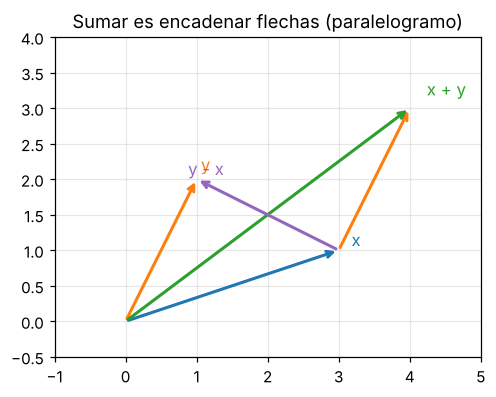

In [2]:
x = np.array([3.0, 1.0])
y = np.array([1.0, 2.0])

print("x + y   =", x + y)
print("2 * x   =", 2 * x)
print("y - x   =", y - x, "  <- la flecha que va de x hasta y")
print("-x      =", -x, "  <- misma longitud, sentido opuesto")

fig, ax = plt.subplots(figsize=(5, 4.5))
flecha(ax, x, color="tab:blue", texto="x")
flecha(ax, y, color="tab:orange", texto="y")
flecha(ax, y, origen=x, color="tab:orange")            # y encadenada después de x
flecha(ax, x + y, color="tab:green", texto="x + y")
flecha(ax, y - x, origen=x, color="tab:purple", texto="y - x")
ax.set_xlim(-1, 5); ax.set_ylim(-0.5, 4); ax.set_aspect("equal")
ax.set_title("Sumar es encadenar flechas (paralelogramo)")
plt.show()

## 👀 Ejemplo 2 · Las tres formas y la trampa del *broadcasting*

Mira con atención la penúltima línea: sumar un vector `(3,)` con uno `(3, 1)` **no da error**. NumPy "estira" ambos y devuelve una matriz de $3\times3$. El programa sigue corriendo con un resultado equivocado. Por eso se revisa el `shape`.

In [3]:
v = np.array([1.0, 2.0, 3.0])
v_col = v.reshape(-1, 1)        # columna
v_fil = v.reshape(1, -1)        # fila
print("v:", v.shape, "| v_col:", v_col.shape, "| v_fil:", v_fil.shape)

u = np.array([10.0, 20.0, 30.0])
print("\nu + v      ->", (u + v).shape, "  (lo esperado)")
print("u + v_col  ->", (u + v_col).shape, "  (¡broadcasting! no es lo que querías)")
print(u + v_col)

# Una imagen de 28x28 aplanada es un punto de R^784
imagen = np.zeros((28, 28))
print("\nimagen:", imagen.shape, "-> aplanada:", imagen.flatten().shape)

v: (3,) | v_col: (3, 1) | v_fil: (1, 3)

u + v      -> (3,)   (lo esperado)
u + v_col  -> (3, 3)   (¡broadcasting! no es lo que querías)
[[11. 21. 31.]
 [12. 22. 32.]
 [13. 23. 33.]]

imagen: (28, 28) -> aplanada: (784,)


#### ✏️ Ejercicio 1.1 · Vector plano y vector columna

Crea el vector $a=(4,-1,2)$ y su versión **columna** con `reshape(-1, 1)`.

> ✅ **Resultado esperado:** `a.shape = (3,)`, `a_col.shape = (3, 1)` y tres ✅.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
a = np.array(___)
a_col = ___

print("a.shape =", a.shape, "| a_col.shape =", a_col.shape)
verificar("a tiene forma (3,)", a.shape == (3,))
verificar("a_col tiene forma (3, 1)", a_col.shape == (3, 1))
verificar("tienen los mismos números", np.array_equal(a, a_col.flatten()) and np.array_equal(a, [4, -1, 2]))

#### ✏️ Ejercicio 1.2 · Las reglas, comprobadas

Comprueba **numéricamente** dos de las 8 reglas con vectores al azar de $\mathbb{R}^5$: la 5, $\alpha(x+y)=\alpha x+\alpha y$, y la 6, $(\alpha+\beta)x=\alpha x+\beta x$. Escribe el **lado derecho** de cada una.

> ✅ **Resultado esperado:** Dos ✅. (Una comprobación numérica no es una demostración: la demostración es la de arriba, coordenada a coordenada.)

In [ ]:
# ✏️ Rellena los ___ y ejecuta
rng = np.random.default_rng(0)
x = rng.normal(size=5)
y = rng.normal(size=5)
alpha, beta = 2.5, -1.2

izq5 = alpha * (x + y)
der5 = ___
izq6 = (alpha + beta) * x
der6 = ___

verificar("regla 5: distributividad sobre vectores", np.allclose(izq5, der5))
verificar("regla 6: distributividad sobre escalares", np.allclose(izq6, der6))

#### ✏️ Ejercicio 1.3 · Predecir y corregir una forma

**La trampa.** Tienes `u` con forma `(4,)` y `v_col` con forma `(4, 1)`. (a) **Predice** la forma de `u + v_col` y escríbela como tupla. (b) Corrige la suma aplanando `v_col` para obtener un vector `(4,)`.

> ✅ **Resultado esperado:** `(4, 4)`; luego `[11. 22. 33. 44.]`.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
u = np.array([1.0, 2.0, 3.0, 4.0])
v_col = np.array([[10.0], [20.0], [30.0], [40.0]])

forma_predicha = ___
suma_bien = u + ___

print("forma real de u + v_col:", (u + v_col).shape)
verificar("predijiste bien la forma", forma_predicha == (u + v_col).shape)
verificar("la suma corregida tiene forma (4,)", suma_bien.shape == (4,))
verificar("y vale [11, 22, 33, 44]", np.array_equal(suma_bien, [11, 22, 33, 44]))

---
# Concepto 2 · Combinación lineal y espacio generado (*span*)

> 🎯 **Objetivo.** Entender qué es mezclar vectores, qué conjunto se obtiene con todas las mezclas posibles, y descubrir que **la salida de una capa de neuronas es una mezcla de las columnas de su matriz**.

## 💡 La historia

Piensa en una pintura con tres tubos: rojo, verde y azul. Cada color que obtienes es una **receta**: tantas gotas de cada tubo. Los tubos son vectores; las cantidades de gotas, los coeficientes; el color resultante, una **combinación lineal**. La pregunta natural es: *¿qué colores puedo fabricar con estos tubos?* El conjunto de todo lo fabricable es el **espacio generado** (en inglés, *span*).

Con un solo tubo solo obtienes tonos de ese color (más o menos intenso). Con dos tubos distintos, una familia entera. Si el segundo tubo es el mismo color que el primero, más diluido, no ganas nada nuevo. Esa última idea es el concepto 3.

## 📐 La matemática

**Definición (combinación lineal).** Dados $v_1,\dots,v_k\in\mathbb{R}^n$ y escalares $\alpha_1,\dots,\alpha_k\in\mathbb{R}$, el vector

$$\alpha_1v_1+\alpha_2v_2+\cdots+\alpha_kv_k=\sum_{j=1}^{k}\alpha_jv_j\in\mathbb{R}^n$$

es una **combinación lineal** de los $v_j$.

**Definición (espacio generado).**

$$\operatorname{span}\{v_1,\dots,v_k\}=\Big\{\,\textstyle\sum_{j=1}^{k}\alpha_jv_j\;:\;\alpha_j\in\mathbb{R}\,\Big\}.$$

**Geometría en $\mathbb{R}^2$ y $\mathbb{R}^3$:**

- el span de un vector $v\neq0$ es la **recta que pasa por el origen** en la dirección de $v$;
- el span de dos vectores no paralelos de $\mathbb{R}^2$ es **todo el plano**;
- en $\mathbb{R}^3$, el span de dos vectores no paralelos es un **plano que pasa por el origen**.

**Teorema (el span es un subespacio).** Si $a,c\in\operatorname{span}\{v_j\}$ y $\lambda\in\mathbb{R}$, entonces $a+c$ y $\lambda a$ también están en el span. *Demostración:* si $a=\sum_j\alpha_jv_j$ y $c=\sum_j\gamma_jv_j$, entonces

$$a+c=\sum_j(\alpha_j+\gamma_j)v_j,\qquad \lambda a=\sum_j(\lambda\alpha_j)v_j,$$

que son otra vez combinaciones lineales. $\blacksquare$ Además siempre contiene al $0$ (todos los $\alpha_j=0$). Por eso el span siempre **pasa por el origen**.

**Las dos lecturas de $Ax$.** Sea $A\in\mathbb{R}^{m\times n}$ con columnas $a^{(1)},\dots,a^{(n)}\in\mathbb{R}^m$, y $x\in\mathbb{R}^n$. Entonces

$$Ax=x_1a^{(1)}+x_2a^{(2)}+\cdots+x_na^{(n)}.$$

Es decir, **$Ax$ es la combinación lineal de las columnas de $A$ cuyos coeficientes son las coordenadas de $x$**. (Se comprueba fila por fila: la coordenada $i$ de ambos lados es $\sum_jA_{ij}x_j$.)

## 🧠 Conexión con la neurona

1. Una capa sin sesgo calcula $Wx$. Por la identidad anterior, **toda salida posible está en el span de las columnas de $W$**. Si ese span es pequeño, la capa no puede producir ciertas salidas, por más que cambie $x$.
2. 🟦 **Un hecho de entrenamiento.** Si los pesos empiezan en $w=0$ y se entrenan con descenso de gradiente, $w$ **siempre** queda en el span de los datos $x^{(1)},\dots,x^{(N)}$. *Demostración por inducción:* al inicio $w=0$ está en el span. Cada paso hace $w\leftarrow w-\eta\sum_i c_i\,x^{(i)}$ (el gradiente de esa neurona es una combinación de los datos; lo dedujimos en el cuaderno anterior), y sumar una combinación de los datos a algo que ya está en el span lo deja en el span (teorema anterior). $\blacksquare$

## 🏷️ Estatus

- 📘 **Definición:** combinación lineal y span.
- 🟦 **Teorema:** el span es un subespacio; $Ax=\sum_jx_ja^{(j)}$; el hecho de entrenamiento del punto 2.

## 🚀 Para qué sirve después

La idea de "representar algo como mezcla de piezas" está en todas partes: una imagen como mezcla de patrones (lo verás en el ejemplo unificador), la compresión JPEG, y los *embeddings* de las redes modernas.

## 👀 Ejemplo 1 · El span de uno y de dos vectores

3·v1 - 2·v2 = [8. 0.]


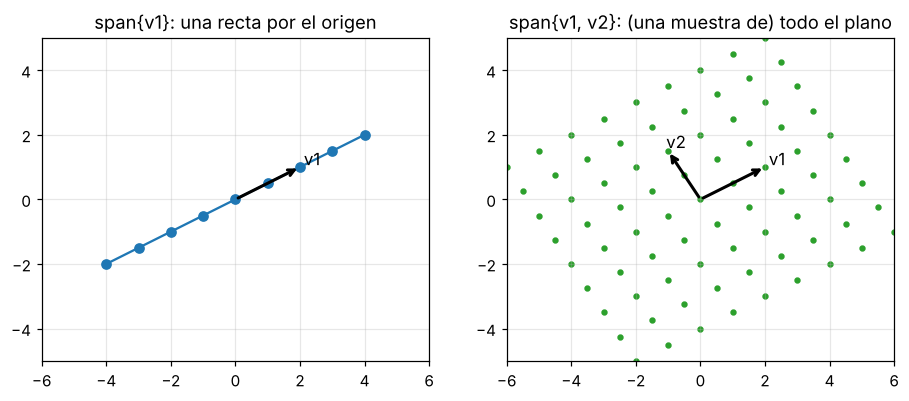

In [7]:
v1 = np.array([2.0, 1.0])
v2 = np.array([-1.0, 1.5])
print("3·v1 - 2·v2 =", 3 * v1 - 2 * v2)

alphas = np.linspace(-2, 2, 9)
fig, axs = plt.subplots(1, 2, figsize=(10, 4.5))

# span{v1}: todos los múltiplos de v1 forman una recta por el origen
puntos = alphas[:, None] * v1                  # (9, 2)
axs[0].plot(*puntos.T, "o-", color="tab:blue")
flecha(axs[0], v1, color="black", texto="v1")
axs[0].set_title("span{v1}: una recta por el origen")

# span{v1, v2}: las combinaciones a·v1 + b·v2 llenan el plano
a, b = np.meshgrid(alphas, alphas)
P = a.ravel()[:, None] * v1 + b.ravel()[:, None] * v2     # (81, 2)
axs[1].scatter(*P.T, s=10, color="tab:green")
flecha(axs[1], v1, color="black", texto="v1"); flecha(axs[1], v2, color="black", texto="v2")
axs[1].set_title("span{v1, v2}: (una muestra de) todo el plano")
for ax in axs:
    ax.set_xlim(-6, 6); ax.set_ylim(-5, 5); ax.set_aspect("equal")
plt.show()

## 👀 Ejemplo 2 · $Wx$ es una combinación de las columnas de $W$

Una "capa" de 2 neuronas con 3 entradas. Calculamos $Wx$ de tres maneras: con `@`, fila por fila (cada fila es una neurona) y columna por columna (la mezcla de columnas).

In [8]:
W = np.array([[1.0, 0.0, 2.0],
              [-1.0, 3.0, 1.0]])        # (2, 3): 2 neuronas, 3 entradas
x = np.array([2.0, -1.0, 0.5])         # (3,)

con_arroba   = W @ x
por_filas    = np.array([W[0] @ x, W[1] @ x])
por_columnas = x[0] * W[:, 0] + x[1] * W[:, 1] + x[2] * W[:, 2]

print("W @ x          :", con_arroba)
print("fila por fila  :", por_filas, "  <- cada neurona hace un producto punto")
print("mezcla columnas:", por_columnas, "  <- x dice cuánto de cada columna")

W @ x          : [ 3.  -4.5]
fila por fila  : [ 3.  -4.5]   <- cada neurona hace un producto punto
mezcla columnas: [ 3.  -4.5]   <- x dice cuánto de cada columna


#### ✏️ Ejercicio 2.1 · Una combinación lineal

Con $v_1=(1,0,2)$, $v_2=(0,1,-1)$ y $v_3=(1,1,1)$, calcula la combinación lineal $c=2v_1-v_2+3v_3$.

> ✅ **Resultado esperado:** $c=(5,2,8)$.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
v1 = np.array([1.0, 0.0, 2.0])
v2 = np.array([0.0, 1.0, -1.0])
v3 = np.array([1.0, 1.0, 1.0])

c = ___

print("c =", c)
verificar("c = (5, 2, 8)", np.array_equal(c, [5, 2, 8]))

#### ✏️ Ejercicio 2.2 · Encontrar los coeficientes

**Encontrar la receta.** Queremos escribir $b=(7,4)$ como $\alpha v_1+\beta v_2$, con $v_1=(1,1)$ y $v_2=(2,0)$. Por la "lectura por columnas", eso es resolver $A\,(\alpha,\beta)^\top=b$ donde **las columnas de $A$ son $v_1$ y $v_2$**. Construye $A$ con `np.column_stack` y resuelve con `np.linalg.solve`.

> 💡 **Pista:** A mano: $\alpha v_1+\beta v_2=(\alpha+2\beta,\ \alpha)$. La segunda coordenada ya te dice $\alpha$.

> ✅ **Resultado esperado:** $(\alpha,\beta)=(4,\ 1.5)$.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
v1 = np.array([1.0, 1.0])
v2 = np.array([2.0, 0.0])
b = np.array([7.0, 4.0])

A_ = ___
coefs = ___

print("A =\n", A_)
print("(alpha, beta) =", coefs)
verificar("A tiene a v1 y v2 como columnas", np.array_equal(A_[:, 0], v1) and np.array_equal(A_[:, 1], v2))
verificar("alpha = 4, beta = 1.5", np.allclose(coefs, [4, 1.5]))
verificar("la receta reconstruye b", np.allclose(coefs[0] * v1 + coefs[1] * v2, b))

#### ✏️ Ejercicio 2.3 · ¿Pertenece al espacio generado?

**¿Está en el span?** Con $v_1=(1,0,1)$ y $v_2=(0,1,1)$, toda combinación es $\alpha v_1+\beta v_2=(\alpha,\ \beta,\ \alpha+\beta)$. Así que, si $b$ está en el span, sus dos primeras coordenadas **obligan** los valores de $\alpha$ y $\beta$, y la tercera debe coincidir. Completa la función con esa idea.

> ✅ **Resultado esperado:** `True` y `False`: el span es un plano de $\mathbb{R}^3$ que no contiene a $(1,2,4)$.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
v1 = np.array([1.0, 0.0, 1.0])
v2 = np.array([0.0, 1.0, 1.0])

def esta_en_span(b):
    alpha = ___
    beta = ___
    return np.allclose(alpha * v1 + beta * v2, b)

print("(1, 2, 3):", esta_en_span(np.array([1.0, 2.0, 3.0])))
print("(1, 2, 4):", esta_en_span(np.array([1.0, 2.0, 4.0])))
verificar("(1, 2, 3) está en el span", esta_en_span(np.array([1.0, 2.0, 3.0])))
verificar("(1, 2, 4) NO está en el span", not esta_en_span(np.array([1.0, 2.0, 4.0])))

---
# Concepto 3 · Independencia lineal, base y dimensión

> 🎯 **Objetivo.** Saber cuándo un conjunto de vectores tiene **información redundante**, qué es una base (el conjunto mínimo que lo genera todo) y por qué las coordenadas en una base son únicas. Y ver la consecuencia práctica: **entradas redundantes hacen que los pesos de una neurona no sean únicos**.

## 💡 La historia

Un robot tiene un sensor de temperatura que reporta en grados Celsius, y por un error de diseño un segundo sensor reporta **la misma** temperatura multiplicada por 2. El segundo sensor no aporta nada: todo lo que dice se deduce del primero. Si le das ambos a una neurona, la neurona puede "repartir" su atención entre los dos de infinitas maneras distintas y obtener **exactamente la misma respuesta**. El entrenamiento no tiene forma de elegir entre ellas.

Eso es la **dependencia lineal**: un vector que se puede fabricar con los demás. Un conjunto sin redundancia es **linealmente independiente**, y uno que además lo genera todo es una **base**.

## 📐 La matemática

**Definición (independencia lineal).** $v_1,\dots,v_k\in\mathbb{R}^n$ son **linealmente independientes** si

$$\alpha_1v_1+\cdots+\alpha_kv_k=0\quad\Longrightarrow\quad\alpha_1=\cdots=\alpha_k=0 .$$

Es decir, la única receta que produce el vector cero es "no usar nada". Si no son independientes, son **dependientes**.

**Equivalencia.** Son dependientes si y solo si alguno es combinación lineal de los otros. *Por qué:* si $\sum_j\alpha_jv_j=0$ con algún $\alpha_\ell\neq0$, despejamos

$$v_\ell=-\sum_{j\neq\ell}\frac{\alpha_j}{\alpha_\ell}\,v_j .$$

Y al revés: si $v_\ell=\sum_{j\neq\ell}\gamma_jv_j$, entonces $v_\ell-\sum_{j\ne\ell}\gamma_jv_j=0$ es una receta no trivial (el coeficiente de $v_\ell$ es $1$).

**Definición (base y dimensión).** Una **base** de un subespacio $S$ es un conjunto de vectores linealmente independientes cuyo span es $S$. 🟦 **Teorema** (lo usamos sin demostrarlo aquí): todas las bases de $S$ tienen el mismo número de vectores, y ese número es la **dimensión** de $S$. En particular, $\dim\mathbb{R}^n=n$, y en $\mathbb{R}^n$ no caben más de $n$ vectores independientes.

**Teorema (las coordenadas en una base son únicas).** Si $\{b_1,\dots,b_n\}$ es base y $x=\sum_j\alpha_jb_j=\sum_j\beta_jb_j$, entonces $\alpha_j=\beta_j$ para todo $j$. *Demostración:* restando,

$$0=\sum_j(\alpha_j-\beta_j)\,b_j ,$$

y por independencia todos los coeficientes son cero: $\alpha_j-\beta_j=0$. $\blacksquare$ A los $\alpha_j$ se les llama **coordenadas de $x$ en esa base**.

**Definición (rango).** El **rango** de una matriz $A$ es el número máximo de columnas linealmente independientes, es decir, la dimensión del span de sus columnas. En NumPy: `np.linalg.matrix_rank(A)`.

> ⚠️ **Cuidado numérico.** En aritmética de punto flotante, "independiente" depende de una **tolerancia**: dos columnas casi paralelas pueden contar como dependientes o no. `matrix_rank` usa la SVD con una tolerancia por defecto razonable (🟧 práctica numérica).

## 🧠 Conexión con la neurona

Si las columnas de la matriz de datos $X\in\mathbb{R}^{N\times n}$ (una columna por entrada) son **dependientes**, existe $v\neq0$ con $Xv=0$. Entonces, para cualquier $w$,

$$X(w+v)=Xw+Xv=Xw .$$

Los pesos $w$ y $w+v$ dan **las mismas salidas para todos los datos**: los pesos no son únicos. En la práctica esto se llama *multicolinealidad*, y se combate eliminando entradas redundantes o con regularización (🟨 heurística).

## 🏷️ Estatus

- 📘 **Definición:** independencia, base, coordenadas, rango.
- 🟦 **Teorema:** la equivalencia con "alguno es combinación de los otros"; unicidad de coordenadas (demostrados arriba); igualdad de tamaño de las bases (citado, no demostrado aquí).

## 🚀 Para qué sirve después

En el proyecto final, que las columnas de los datos sean independientes es **exactamente** la condición para que el entrenamiento por mínimos cuadrados tenga solución única.

## 👀 Ejemplo 1 · Medir la independencia con el rango, y coordenadas en una base

In [12]:
v1 = np.array([1.0, 0.0, 2.0])
v2 = np.array([0.0, 1.0, 1.0])
v3 = v1 + 2 * v2                       # dependiente a propósito

A_dep = np.column_stack([v1, v2, v3])
print("A_dep =\n", A_dep)
print("rango:", np.linalg.matrix_rank(A_dep), "de", A_dep.shape[1], "columnas  -> dependientes")

e3 = np.array([0.0, 0.0, 1.0])
B = np.column_stack([v1, v2, e3])
print("\nrango de [v1 v2 e3]:", np.linalg.matrix_rank(B), "-> es una base de R^3")

# Coordenadas de x en la base {v1, v2, e3}: resolver B c = x
x = np.array([3.0, -1.0, 4.0])
c = np.linalg.solve(B, x)
print("coordenadas de x en esa base:", c)
print("reconstrucción B @ c        :", B @ c)

A_dep =
 [[1. 0. 1.]
 [0. 1. 2.]
 [2. 1. 4.]]
rango: 2 de 3 columnas  -> dependientes

rango de [v1 v2 e3]: 3 -> es una base de R^3
coordenadas de x en esa base: [ 3. -1. -1.]
reconstrucción B @ c        : [ 3. -1.  4.]


## 👀 Ejemplo 2 · Entradas redundantes $\Rightarrow$ pesos no únicos

La segunda entrada es el doble de la primera. Tres vectores de pesos **distintos** producen **exactamente** las mismas salidas.

In [13]:
rng = np.random.default_rng(0)
x1 = rng.normal(size=6)
X = np.column_stack([x1, 2 * x1])      # (6, 2): la columna 2 es el doble de la 1
print("rango de X:", np.linalg.matrix_rank(X), "de", X.shape[1], "columnas")

w_a = np.array([1.0, 0.0])
w_b = np.array([-1.0, 1.0])
w_c = np.array([3.0, -1.0])
print("X @ w_a:", X @ w_a)
print("X @ w_b:", X @ w_b)
print("X @ w_c:", X @ w_c)

v = w_a - w_b                          # la diferencia está en el núcleo: X v = 0
print("\nv = w_a - w_b =", v, "-> X @ v =", X @ v)

rango de X: 1 de 2 columnas
X @ w_a: [ 0.1257 -0.1321  0.6404  0.1049 -0.5357  0.3616]
X @ w_b: [ 0.1257 -0.1321  0.6404  0.1049 -0.5357  0.3616]
X @ w_c: [ 0.1257 -0.1321  0.6404  0.1049 -0.5357  0.3616]

v = w_a - w_b = [ 2. -1.] -> X @ v = [0. 0. 0. 0. 0. 0.]


#### ✏️ Ejercicio 3.1 · El rango

Calcula el rango de $M$ y decide si sus columnas son independientes (lo son si el rango es igual al número de columnas).

> ✅ **Resultado esperado:** Rango $2$ y `False`. (La fila 2 es el doble de la fila 1.)

In [ ]:
# ✏️ Rellena los ___ y ejecuta
M = np.array([[1.0, 2.0, 3.0],
              [2.0, 4.0, 6.0],
              [1.0, 0.0, 1.0]])

rango = ___
son_independientes = ___

print("rango =", rango, "| ¿independientes?", son_independientes)
verificar("rango = 2", rango == 2)
verificar("las columnas son dependientes", not son_independientes)

#### ✏️ Ejercicio 3.2 · Coordenadas en una base

**Coordenadas en otra base.** Con la base $b_1=(1,1)$, $b_2=(1,-1)$, encuentra las coordenadas $(\alpha,\beta)$ de $x=(5,1)$, es decir, $x=\alpha b_1+\beta b_2$.

> 💡 **Pista:** A mano: $\alpha+\beta=5$ y $\alpha-\beta=1$. Suma las dos ecuaciones.

> ✅ **Resultado esperado:** $(\alpha,\beta)=(3,2)$.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
b1 = np.array([1.0, 1.0])
b2 = np.array([1.0, -1.0])
x = np.array([5.0, 1.0])

B = ___
coords = ___

print("coordenadas =", coords)
verificar("alpha = 3, beta = 2", np.allclose(coords, [3, 2]))
verificar("reconstruyen x", np.allclose(coords[0] * b1 + coords[1] * b2, x))

#### ✏️ Ejercicio 3.3 · La receta escondida

**Encuentra la dependencia a mano.** Con $v_1=(1,2,0)$, $v_2=(0,1,1)$ y $v_3=(2,3,-1)$, encuentra $a$ y $b$ tales que $v_3=a\,v_1+b\,v_2$.

> 💡 **Pista:** La primera coordenada de $a v_1+b v_2$ es solo $a$ (porque $v_2$ empieza en $0$). La tercera es solo $b$.

> ✅ **Resultado esperado:** $a=2$, $b=-1$.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
v1 = np.array([1.0, 2.0, 0.0])
v2 = np.array([0.0, 1.0, 1.0])
v3 = np.array([2.0, 3.0, -1.0])

a = ___
b = ___

print("a v1 + b v2 =", a * v1 + b * v2)
verificar("v3 = a v1 + b v2", np.allclose(a * v1 + b * v2, v3))
verificar("por eso el rango de [v1 v2 v3] es 2", np.linalg.matrix_rank(np.column_stack([v1, v2, v3])) == 2)

---
# Concepto 4 · Producto punto, norma y ángulo

> 🎯 **Objetivo.** Entender el producto punto como la forma de **comparar** dos vectores, demostrar la desigualdad de Cauchy–Schwarz y descubrir su consecuencia para la neurona: **$w$ es el patrón que la neurona busca**, y responde al máximo cuando la entrada se le parece.

## 💡 La historia

Tienes una foto de referencia de un tornillo y llega una foto nueva. ¿Se parecen? Una manera simple de medirlo: multiplica píxel a píxel y suma. Donde ambas son claras, la suma crece; donde una es clara y la otra oscura, decrece. Ese número es el **producto punto**, y es exactamente lo que hace una neurona con sus entradas y sus pesos. Los pesos son la "foto de referencia" de la neurona. A esta idea se le llama ***template matching*** (comparación con una plantilla).

Pero hay un problema: si la foto nueva es simplemente más brillante, el producto crece aunque no se parezca más. Para separar el **parecido** de la **intensidad** necesitamos la **norma** (la longitud) y el **ángulo**.

## 📐 La matemática

**Definición (producto punto).** Para $x,y\in\mathbb{R}^n$,

$$x\cdot y=x^\top y=\sum_{i=1}^{n}x_iy_i\in\mathbb{R}.$$

Cumple tres propiedades, y cualquier operación que las cumpla se llama **producto interno**:

1. simetría: $x\cdot y=y\cdot x$;
2. linealidad en cada entrada: $(\alpha x+u)\cdot y=\alpha\,(x\cdot y)+u\cdot y$;
3. positividad: $x\cdot x=\sum_ix_i^2\geq0$, con igualdad solo si $x=0$.

**Definición (norma).**

$$\lVert x\rVert=\sqrt{x\cdot x}=\sqrt{x_1^2+\cdots+x_n^2}.$$

En $\mathbb{R}^2$ es el teorema de Pitágoras. Un vector es **unitario** si $\lVert u\rVert=1$; todo $x\neq0$ se normaliza como

$$\hat{x}=\frac{x}{\lVert x\rVert}.$$

**Teorema (Cauchy–Schwarz).** Para todo $x,y\in\mathbb{R}^n$,

$$\lvert x\cdot y\rvert\leq\lVert x\rVert\,\lVert y\rVert,$$

con igualdad si y solo si uno es múltiplo del otro.

*Demostración.* Si $y=0$ ambos lados valen $0$. Si $y\neq0$, para todo $t\in\mathbb{R}$ la positividad da

$$0\leq\lVert x-ty\rVert^2=(x-ty)\cdot(x-ty)=\lVert x\rVert^2-2t\,(x\cdot y)+t^2\lVert y\rVert^2 .$$

Elegimos el $t$ que hace más pequeño el lado derecho (el vértice de esa parábola en $t$):

$$t=\frac{x\cdot y}{\lVert y\rVert^2}.$$

Sustituyendo:

$$0\leq\lVert x\rVert^2-2\,\frac{(x\cdot y)^2}{\lVert y\rVert^2}+\frac{(x\cdot y)^2}{\lVert y\rVert^2}=\lVert x\rVert^2-\frac{(x\cdot y)^2}{\lVert y\rVert^2}.$$

Multiplicando por $\lVert y\rVert^2>0$: $(x\cdot y)^2\leq\lVert x\rVert^2\lVert y\rVert^2$, y sacando raíz se obtiene el resultado. La igualdad ocurre exactamente cuando $\lVert x-ty\rVert=0$, es decir, $x=ty$. $\blacksquare$

**Definición (ángulo).** Para $x,y\neq0$, Cauchy–Schwarz garantiza que el cociente siguiente está en $[-1,1]$, así que podemos **definir** el ángulo $\theta\in[0,\pi]$ por

$$\cos\theta=\frac{x\cdot y}{\lVert x\rVert\,\lVert y\rVert}.$$

En $\mathbb{R}^2$ coincide con el ángulo geométrico (ley de cosenos; está en tu documento de fundamentos). En $\mathbb{R}^{784}$ no lo "vemos", pero la fórmula sigue funcionando. Ese cociente se llama **similitud de coseno**: mide el parecido **sin importar la intensidad**.

## 🧠 Conexión con la neurona

Reescribiendo, la parte lineal de la neurona es

$$w^\top x=\lVert w\rVert\,\lVert x\rVert\cos\theta .$$

Para entradas de longitud fija, la respuesta es **máxima** cuando $x$ apunta como $w$ ($\theta=0$), **cero** cuando son perpendiculares y **mínima** cuando apuntan en sentidos opuestos.

🟦 **Corolario.** Entre todos los vectores unitarios $u$, el valor máximo de $w^\top u$ es $\lVert w\rVert$, y se alcanza en $u=\hat w$. *Prueba:* por Cauchy–Schwarz, $w^\top u\leq\lVert w\rVert\,\lVert u\rVert=\lVert w\rVert$, y con $u=\hat w$ se obtiene la igualdad. Por eso decimos que **$w$ es el patrón preferido de la neurona**.

## 🏷️ Estatus

- 📘 **Definición:** producto punto, norma, ángulo, similitud de coseno.
- 🟦 **Teorema:** Cauchy–Schwarz y el corolario (demostrados arriba).
- 🟧 **Práctica empírica:** los filtros de la primera capa de una red convolucional entrenada suelen parecerse a detectores de bordes. Es una observación repetida, no un teorema.

## 🚀 Para qué sirve después

En visión por computador, un filtro convolucional **es** una plantilla que se compara, con un producto punto, contra cada parche de la imagen. Y la similitud de coseno es la forma estándar de comparar *embeddings* (por ejemplo, en reconocimiento facial).

## 👀 Ejemplo 1 · Tres formas de calcular, norma y ángulo

In [17]:
x = np.array([1.0, 2.0, 2.0])
y = np.array([2.0, 0.0, 1.0])

total = 0.0                             # desde cero: la definición
for xi, yi in zip(x, y):
    total += xi * yi
print("con ciclo :", total, "| con np.dot:", np.dot(x, y), "| con @:", x @ y)

print("\n||x|| desde cero:", np.sqrt(x @ x), "| con np.linalg.norm:", np.linalg.norm(x))

cos_theta = (x @ y) / (np.linalg.norm(x) * np.linalg.norm(y))
print("cos(theta) =", cos_theta, "-> theta =", np.degrees(np.arccos(cos_theta)), "grados")

# La similitud de coseno no cambia si una entrada se vuelve "más brillante"
cos_brillante = (x @ (5 * y)) / (np.linalg.norm(x) * np.linalg.norm(5 * y))
print("x·(5y) =", x @ (5 * y), "(creció) pero el coseno sigue siendo", cos_brillante)

con ciclo : 4.0 | con np.dot: 4.0 | con @: 4.0

||x|| desde cero: 3.0 | con np.linalg.norm: 3.0
cos(theta) = 0.5962847939999439 -> theta = 53.395723557294346 grados
x·(5y) = 20.0 (creció) pero el coseno sigue siendo 0.5962847939999438


## 👀 Ejemplo 2 · Una neurona que busca bordes verticales (*template matching*)

Los pesos son una imagen de $3\times3$: oscuro a la izquierda ($-1$), claro a la derecha ($+1$). Comparamos contra cinco parches. Fíjate en que el parche constante y el borde horizontal dan respuesta $0$: son **perpendiculares** a la plantilla.

borde vertical       w·x =  3.000 | coseno =  0.632
vertical con ruido   w·x =  3.395 | coseno =  0.651
borde invertido      w·x = -3.000 | coseno = -0.632
borde horizontal     w·x =  0.000 | coseno =  0.000
constante            w·x =  0.000 | coseno =  0.000


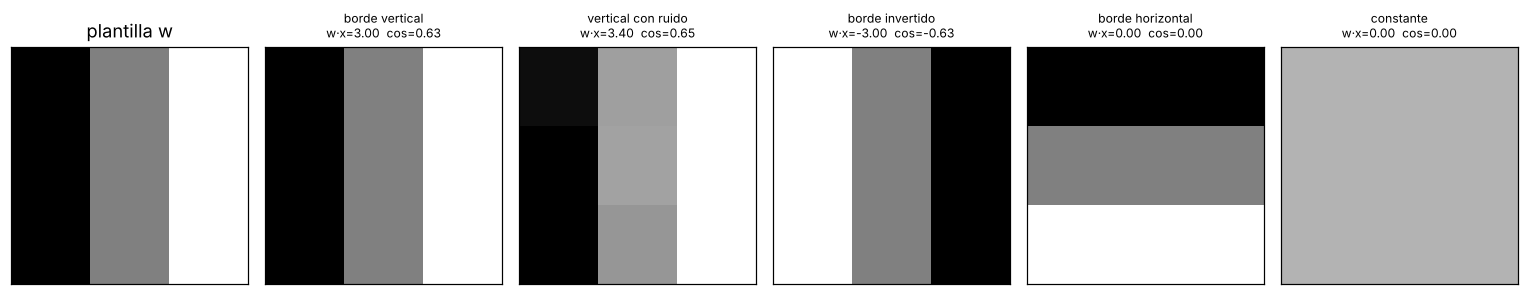

In [18]:
plantilla = np.array([[-1, 0, 1],
                      [-1, 0, 1],
                      [-1, 0, 1]], dtype=float)
w = plantilla.flatten()                                   # pesos en R^9

rng = np.random.default_rng(1)
parches = {
    "borde vertical":     np.array([[0.0, 0.5, 1.0]] * 3),
    "vertical con ruido": np.array([[0.0, 0.5, 1.0]] * 3) + rng.normal(scale=0.15, size=(3, 3)),
    "borde invertido":    np.array([[1.0, 0.5, 0.0]] * 3),
    "borde horizontal":   np.array([[0.0] * 3, [0.5] * 3, [1.0] * 3]),
    "constante":          np.full((3, 3), 0.7),
}

fig, axs = plt.subplots(1, 6, figsize=(14, 2.8))
axs[0].imshow(plantilla, cmap="gray"); axs[0].set_title("plantilla w")
for ax, (nombre, p) in zip(axs[1:], parches.items()):
    x = p.flatten()
    s = w @ x
    cos = s / (np.linalg.norm(w) * np.linalg.norm(x))
    ax.imshow(p, cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"{nombre}\nw·x={s:.2f}  cos={cos:.2f}", fontsize=8)
    print(f"{nombre:<20} w·x = {s:6.3f} | coseno = {cos:6.3f}")
for ax in axs:
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.tight_layout(); plt.show()

#### ✏️ Ejercicio 4.1 · Desde cero

Implementa `mi_punto(x, y)` con un ciclo y `mi_norma(x)` usando `mi_punto`. Pruébalas con $x=(1,2,2)$ y $y=(3,0,-4)$.

> ✅ **Resultado esperado:** $x\cdot y=-5$, $\lVert x\rVert=3$, $\lVert y\rVert=5$.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
def mi_punto(x, y):
    total = 0.0
    for xi, yi in zip(x, y):
        total += ___
    return total

def mi_norma(x):
    return ___

x = np.array([1.0, 2.0, 2.0])
y = np.array([3.0, 0.0, -4.0])
print("x·y =", mi_punto(x, y), "| ||x|| =", mi_norma(x), "| ||y|| =", mi_norma(y))
verificar("x·y = -5", np.isclose(mi_punto(x, y), -5))
verificar("||x|| = 3 y ||y|| = 5", np.isclose(mi_norma(x), 3) and np.isclose(mi_norma(y), 5))
verificar("coinciden con NumPy", np.isclose(mi_punto(x, y), x @ y) and np.isclose(mi_norma(y), np.linalg.norm(y)))

#### ✏️ Ejercicio 4.2 · Cauchy–Schwarz numérico

**Cauchy–Schwarz, puesto a prueba.** Para 1000 parejas al azar en $\mathbb{R}^6$ (filas de `X` y de `Y`), calcula en un solo paso $\lvert x\cdot y\rvert$ (lado izquierdo) y $\lVert x\rVert\,\lVert y\rVert$ (lado derecho). Luego comprueba la **igualdad** cuando $y=-3x$.

> 💡 **Pista:** `np.sum(X * Y, axis=1)` hace el producto punto de cada fila de `X` con la fila correspondiente de `Y`.

> ✅ **Resultado esperado:** El cociente máximo queda por debajo de $1$, y tres ✅.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
rng = np.random.default_rng(2)
X = rng.normal(size=(1000, 6))
Y = rng.normal(size=(1000, 6))

izq = ___
der = ___

x = X[0]; y = -3 * x
print("máximo de izq/der en las 1000 parejas:", np.max(izq / der))
verificar("izq y der tienen forma (1000,)", izq.shape == (1000,) and der.shape == (1000,))
verificar("Cauchy–Schwarz se cumple en las 1000 parejas", np.all(izq <= der + 1e-12))
verificar("hay igualdad cuando y = -3x", np.isclose(abs(x @ y), np.linalg.norm(x) * np.linalg.norm(y)))

#### ✏️ Ejercicio 4.3 · El patrón preferido

**¿Qué entrada prefiere la neurona?** Con $w=(3,4)$, prueba 3600 vectores unitarios $u=(\cos\varphi,\sin\varphi)$ de $\mathbb{R}^2$. Calcula todas las respuestas $w^\top u$ con una sola expresión matricial y encuentra el $u$ con la respuesta máxima. Debe ser casi $\hat w=(0.6,\,0.8)$, con respuesta casi $\lVert w\rVert=5$.

> ✅ **Resultado esperado:** $u\approx(0.6,\ 0.8)$ y respuesta $\approx5$: el corolario de Cauchy–Schwarz, visto numéricamente.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
w = np.array([3.0, 4.0])
phi = np.linspace(0, 2 * np.pi, 3600, endpoint=False)
U = np.column_stack([np.cos(phi), np.sin(phi)])          # (3600, 2): cada fila es unitaria

respuestas = ___
mejor_u = ___

print("mejor u =", mejor_u, "| respuesta máxima =", respuestas.max())
verificar("respuestas tiene forma (3600,)", respuestas.shape == (3600,))
verificar("el mejor u es casi w/||w||", np.allclose(mejor_u, w / np.linalg.norm(w), atol=2e-3))
verificar("la respuesta máxima es casi ||w|| = 5", np.isclose(respuestas.max(), 5, atol=1e-3))

---
# Concepto 5 · Ortogonalidad y proyección

> 🎯 **Objetivo.** Entender la perpendicularidad como "producto punto cero", deducir la fórmula de la **proyección** sobre una recta y sobre un subespacio (las **ecuaciones normales**) y demostrar que la proyección es **el punto más cercano**. Este es el concepto que usaremos para **entrenar** la neurona del proyecto.

## 💡 La historia

Es mediodía y el sol cae vertical sobre un poste inclinado. Su sombra en el suelo es su **proyección**: la parte del poste que "va a lo largo del suelo". Lo que falta para llegar a la punta del poste es un segmento **perpendicular** al suelo. Toda la geometría de esta sección cabe en esa imagen: un vector se parte en una pieza **a lo largo** de algo y otra pieza **perpendicular** a ese algo.

Y hay un premio. Si alguien te pide el punto del suelo **más cercano** a la punta del poste, la respuesta es la punta de la sombra. "Mejor aproximación" y "proyección" son la misma cosa. Gran parte del aprendizaje automático es buscar mejores aproximaciones.

## 📐 La matemática

**Ortogonalidad.** $x\perp y\iff x\cdot y=0$ (porque $\cos\theta=0$ cuando $\theta=90^\circ$; para el vector $0$ lo tomamos como definición).

**Teorema (Pitágoras en $\mathbb{R}^n$).** Si $x\perp y$, entonces $\lVert x+y\rVert^2=\lVert x\rVert^2+\lVert y\rVert^2$. *Demostración:*

$$\lVert x+y\rVert^2=(x+y)\cdot(x+y)=\lVert x\rVert^2+2\,\underbrace{x\cdot y}_{=0}+\lVert y\rVert^2 .\qquad\blacksquare$$

**Proyección sobre una recta.** Sea $u\in\mathbb{R}^n$, $u\neq0$. Buscamos $p=\alpha u$ (un punto de la recta $\operatorname{span}\{u\}$) tal que el resto $r=x-p$ sea perpendicular a $u$:

$$(x-\alpha u)\cdot u=0\;\Longrightarrow\;x\cdot u-\alpha\,(u\cdot u)=0\;\Longrightarrow\;\alpha=\frac{x\cdot u}{u\cdot u}.$$

Por tanto

$$\operatorname{proy}_u(x)=\frac{x\cdot u}{u\cdot u}\,u,\qquad x=\underbrace{\operatorname{proy}_u(x)}_{\text{a lo largo de }u}+\underbrace{r}_{\perp\,u}.$$

Si $u$ es unitario, se simplifica a $\operatorname{proy}_u(x)=(x\cdot u)\,u$.

**Teorema (la proyección es el punto más cercano).** Para cualquier punto $\beta u$ de la recta,

$$\lVert x-\beta u\rVert^2=\lVert r+(\alpha-\beta)u\rVert^2=\lVert r\rVert^2+(\alpha-\beta)^2\lVert u\rVert^2\geq\lVert r\rVert^2,$$

donde la segunda igualdad es Pitágoras ($r\perp u$). La igualdad ocurre solo si $\beta=\alpha$. $\blacksquare$

**Proyección sobre un subespacio (ecuaciones normales).** Sea $A\in\mathbb{R}^{n\times k}$ con columnas $a^{(1)},\dots,a^{(k)}$ **linealmente independientes**. Buscamos el punto $p=Ac$ (con $c\in\mathbb{R}^k$) del span de las columnas tal que el resto $r=x-Ac$ sea perpendicular a **todas** las columnas. Las $k$ condiciones $a^{(j)}\cdot r=0$ se escriben juntas como $A^\top r=0$:

$$A^\top(x-Ac)=0\quad\Longrightarrow\quad\boxed{\,A^\top A\,c=A^\top x\,}$$

Estas son las **ecuaciones normales**. La matriz $A^\top A\in\mathbb{R}^{k\times k}$ es **invertible** cuando las columnas son independientes. *Demostración:* si $A^\top Ac=0$, entonces

$$0=c^\top A^\top Ac=(Ac)\cdot(Ac)=\lVert Ac\rVert^2,$$

así que $Ac=0$; por independencia de las columnas, $c=0$. Una matriz cuadrada cuyo único vector anulado es el $0$ es invertible. $\blacksquare$ Con el mismo argumento de Pitágoras, $Ac$ es el punto del subespacio más cercano a $x$: resuelve el problema de **mínimos cuadrados**

$$\min_{c\in\mathbb{R}^k}\lVert x-Ac\rVert^2 .$$

## 🧠 Conexión con la neurona

1. La respuesta lineal $w^\top x$ depende **solo** de la proyección de $x$ sobre $w$ (lo veremos a fondo en el concepto 8).
2. **Entrenar** una neurona lineal por mínimos cuadrados es **proyectar** el vector de etiquetas $y\in\mathbb{R}^N$ sobre el subespacio generado por las columnas de la matriz de datos. Es el proyecto final.

## 🏷️ Estatus

- 🟦 **Teorema:** Pitágoras, fórmula de la proyección, punto más cercano, invertibilidad de $A^\top A$ (todos demostrados arriba).
- 🟦 **Resultado de análisis numérico:** resolver las ecuaciones normales **eleva al cuadrado** el número de condición del problema. Por eso, en problemas grandes o mal condicionados se prefiere `np.linalg.lstsq` (basado en descomposiciones ortogonales). Aquí, con problemas pequeños, ambos sirven.

## 🚀 Para qué sirve después

Mínimos cuadrados es la base de la regresión lineal, de la calibración de cámaras y sensores en robótica, y de los filtros de estimación como el de Kalman.

## 👀 Ejemplo 1 · Proyectar sobre una recta (y comprobar que es el punto más cercano)

alpha = 0.6 | proyección p = [1.8 0.6] | resto r = [-0.8  2.4]
r·u = 4.440892098500626e-16 -> el resto es perpendicular a u
Pitágoras: ||x||² = 10.0 = 3.599999999999999 + 6.3999999999999995


beta más cercano (a ciegas): 0.6000000000000001 | alpha (fórmula): 0.6


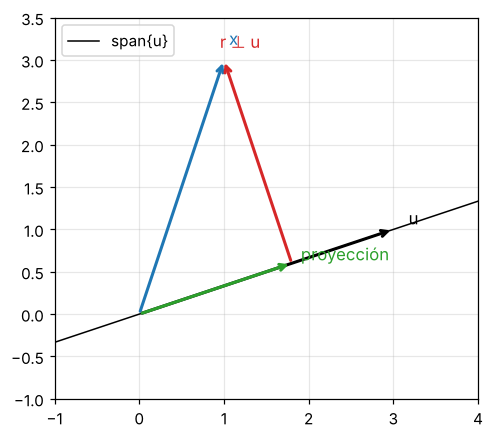

In [22]:
x = np.array([1.0, 3.0])
u = np.array([3.0, 1.0])

alpha = (x @ u) / (u @ u)
p = alpha * u
r = x - p
print("alpha =", alpha, "| proyección p =", p, "| resto r =", r)
print("r·u =", r @ u, "-> el resto es perpendicular a u")
print("Pitágoras: ||x||² =", x @ x, "=", p @ p, "+", r @ r)

# Búsqueda a ciegas: el punto beta·u más cercano a x
betas = np.linspace(-2, 2, 40001)
distancias = np.linalg.norm(x - betas[:, None] * u, axis=1)
print("beta más cercano (a ciegas):", betas[np.argmin(distancias)], "| alpha (fórmula):", alpha)

fig, ax = plt.subplots(figsize=(5, 4.5))
recta = np.array([-1.5, 1.5])[:, None] * u
ax.plot(*recta.T, "k-", lw=1, label="span{u}")
flecha(ax, x, color="tab:blue", texto="x")
flecha(ax, u, color="black", texto="u")
flecha(ax, p, color="tab:green", texto="proyección")
flecha(ax, r, origen=p, color="tab:red", texto="r ⊥ u")
ax.set_xlim(-1, 4); ax.set_ylim(-1, 3.5); ax.set_aspect("equal"); ax.legend(loc="upper left")
plt.show()

## 👀 Ejemplo 2 · Proyectar sobre un plano de $\mathbb{R}^3$: ecuaciones normales vs. librería

In [23]:
a1 = np.array([1.0, 0.0, 1.0])
a2 = np.array([0.0, 1.0, 1.0])
A_ = np.column_stack([a1, a2])          # (3, 2): el plano es el span de sus columnas
x = np.array([1.0, 2.0, 6.0])

# Desde cero: ecuaciones normales
G = A_.T @ A_                           # (2, 2)
h = A_.T @ x                            # (2,)
c = np.linalg.solve(G, h)
p = A_ @ c
r = x - p
print("A^T A =\n", G, "\nA^T x =", h)
print("c =", c, "| proyección p =", p, "| resto r =", r)
print("A^T r =", A_.T @ r, "-> r es perpendicular a las dos columnas")

# Con librería
c_lib, *_ = np.linalg.lstsq(A_, x, rcond=None)
print("np.linalg.lstsq da c =", c_lib)

A^T A =
 [[2. 1.]
 [1. 2.]] 
A^T x = [7. 8.]
c = [2. 3.] | proyección p = [2. 3. 5.] | resto r = [-1. -1.  1.]
A^T r = [0. 0.] -> r es perpendicular a las dos columnas
np.linalg.lstsq da c = [2. 3.]


#### ✏️ Ejercicio 5.1 · Proyección sobre una recta

Proyecta $x=(3,4)$ sobre $u=(2,1)$: calcula $\alpha$, la proyección $p=\alpha u$ y el resto $r=x-p$.

> ✅ **Resultado esperado:** $\alpha=2$, $p=(4,2)$, $r=(-1,2)$.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
x = np.array([3.0, 4.0])
u = np.array([2.0, 1.0])

alpha = ___
p = ___
r = ___

print("alpha =", alpha, "| p =", p, "| r =", r)
verificar("alpha = 2", np.isclose(alpha, 2))
verificar("p = (4, 2) y r = (-1, 2)", np.allclose(p, [4, 2]) and np.allclose(r, [-1, 2]))
verificar("r es perpendicular a u", np.isclose(r @ u, 0))

#### ✏️ Ejercicio 5.2 · Pitágoras en acción

**Pitágoras.** Con el mismo $x=(3,4)$ y $u=(2,1)$, comprueba que $\lVert x\rVert^2=\lVert p\rVert^2+\lVert r\rVert^2$. Calcula los tres cuadrados con productos punto.

> ✅ **Resultado esperado:** $25=20+5$.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
x = np.array([3.0, 4.0])
u = np.array([2.0, 1.0])
p = (x @ u) / (u @ u) * u
r = x - p

nx2 = ___
np2 = ___
nr2 = ___

print(nx2, "=", np2, "+", nr2)
verificar("25 = 20 + 5", np.isclose(nx2, 25) and np.isclose(np2, 20) and np.isclose(nr2, 5))
verificar("se cumple Pitágoras", np.isclose(nx2, np2 + nr2))

#### ✏️ Ejercicio 5.3 · Mínimos cuadrados

**Ajustar una recta es proyectar.** Queremos la recta $y=c_0+c_1t$ más cercana (en mínimos cuadrados) a los puntos $(t,y)=(0,1),(1,2),(2,4)$. Cada punto da una ecuación $c_0+c_1t_i\approx y_i$, así que $A$ tiene una columna de unos y una columna con los $t_i$. Resuelve las **ecuaciones normales**, calcula el resto y compara con `lstsq`.

> ✅ **Resultado esperado:** $c_0=\frac{5}{6}\approx0.8333$ y $c_1=1.5$, y tres ✅.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
t = np.array([0.0, 1.0, 2.0])
y = np.array([1.0, 2.0, 4.0])
A_ = np.column_stack([np.ones(3), t])          # (3, 2)

c = ___
r = ___

c_lib, *_ = np.linalg.lstsq(A_, y, rcond=None)
print("c (ecuaciones normales) =", c, "| c (lstsq) =", c_lib)
print("A^T r =", A_.T @ r)
verificar("c0 = 5/6 y c1 = 3/2", np.allclose(c, [5 / 6, 1.5]))
verificar("el resto es perpendicular a las columnas de A", np.allclose(A_.T @ r, 0))
verificar("coincide con np.linalg.lstsq", np.allclose(c, c_lib))

---
# Concepto 6 · Matrices como transformaciones lineales

> 🎯 **Objetivo.** Entender que una matriz **es** una función que transforma vectores, que sus columnas son las imágenes de los vectores de la base y que, leída por filas, **cada fila es una neurona**: una capa de neuronas es una matriz.

## 💡 La historia

Imagina una hoja de papel cuadriculado elástico. Puedes girarla, estirarla en una dirección o inclinarla como un mazo de cartas. Hay una regla: las líneas de la cuadrícula deben seguir **rectas, paralelas y equiespaciadas**, y el origen no se mueve. Esas son las **transformaciones lineales**.

Lo extraordinario es que, para saber qué le pasa a **toda** la hoja, basta mirar a dónde van **dos flechas**: la que apunta al este, $e_1=(1,0)$, y la que apunta al norte, $e_2=(0,1)$. Todo lo demás queda determinado. Y si escribes esas dos flechas como columnas, obtienes la **matriz** de la transformación.

## 📐 La matemática

**Definición (transformación lineal).** $T:\mathbb{R}^n\to\mathbb{R}^m$ es lineal si para todo $x,y\in\mathbb{R}^n$ y $\alpha\in\mathbb{R}$:

$$T(x+y)=T(x)+T(y),\qquad T(\alpha x)=\alpha\,T(x).$$

Consecuencia inmediata: $T(0)=T(0\cdot0)=0\cdot T(0)=0$. **Una transformación lineal siempre fija el origen.**

**Teorema (toda transformación lineal es una matriz).** Sea $e_j\in\mathbb{R}^n$ el vector con un $1$ en la posición $j$ y $0$ en las demás. Si $T$ es lineal, existe una única matriz $A\in\mathbb{R}^{m\times n}$ con $T(x)=Ax$ para todo $x$, y sus columnas son

$$A=\big[\,T(e_1)\;\big|\;T(e_2)\;\big|\;\cdots\;\big|\;T(e_n)\,\big].$$

*Demostración.* Todo $x$ se escribe como $x=\sum_jx_je_j$. Por linealidad,

$$T(x)=T\Big(\sum_jx_je_j\Big)=\sum_jx_j\,T(e_j)=Ax,$$

donde la última igualdad es la "lectura por columnas" del concepto 2. Es única porque las columnas quedan obligadas: $Ae_j$ es la columna $j$ de $A$. $\blacksquare$

**Las dos lecturas de $Ax$**, ahora con nombre. Si $a_i^\top$ es la fila $i$ de $A$ y $a^{(j)}$ su columna $j$:

$$(Ax)_i=a_i^\top x\quad\text{(por filas: un producto punto por fila)},\qquad Ax=\sum_jx_j\,a^{(j)}\quad\text{(por columnas)}.$$

**Ejemplos en $\mathbb{R}^2$:**

| Transformación | Matriz |
|---|---|
| Rotación por un ángulo $\varphi$ | $R_\varphi=\begin{pmatrix}\cos\varphi&-\sin\varphi\\ \sin\varphi&\cos\varphi\end{pmatrix}$ |
| Escalado | $\begin{pmatrix}s_1&0\\0&s_2\end{pmatrix}$ |
| Cizalla (*shear*) | $\begin{pmatrix}1&k\\0&1\end{pmatrix}$ |
| Proyección sobre el eje horizontal | $\begin{pmatrix}1&0\\0&0\end{pmatrix}$ |

## 🧠 Conexión con la neurona

Una **capa** de $m$ neuronas, cada una con pesos $w_i\in\mathbb{R}^n$, se escribe apilando los pesos **como filas**:

$$W=\begin{pmatrix}w_1^\top\\ \vdots\\ w_m^\top\end{pmatrix}\in\mathbb{R}^{m\times n},\qquad (Wx)_i=w_i^\top x .$$

La lectura por filas dice: **cada fila es una neurona** haciendo su producto punto. Y una sola neurona es el caso $m=1$: una matriz $1\times n$, la función lineal $x\mapsto w^\top x$ de $\mathbb{R}^n$ en $\mathbb{R}$.

## 🏷️ Estatus

- 📘 **Definición:** transformación lineal; matriz de una capa.
- 🟦 **Teorema:** representación matricial (demostrado arriba); $T(0)=0$.

## 🚀 Para qué sirve después

Rotaciones y escalados son el día a día de la robótica (orientación de un brazo, de una cámara). En visión, el aumento de datos (*data augmentation*) rota y escala imágenes con estas mismas matrices.

## 👀 Ejemplo 1 · Qué le hacen cuatro matrices a la cuadrícula

La flecha azul es la imagen de $e_1$ y la naranja la de $e_2$: son las **columnas** de cada matriz.

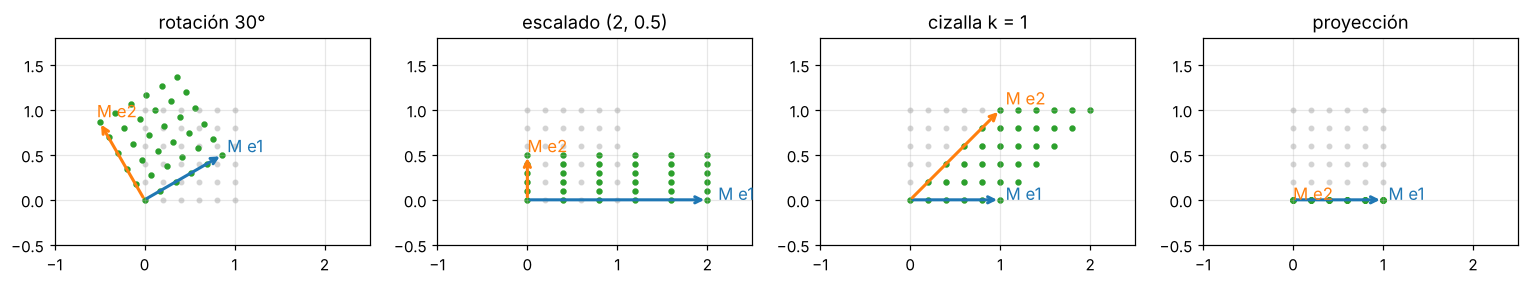

In [27]:
phi = np.pi / 6
matrices = {
    "rotación 30°": np.array([[np.cos(phi), -np.sin(phi)], [np.sin(phi), np.cos(phi)]]),
    "escalado (2, 0.5)": np.array([[2.0, 0.0], [0.0, 0.5]]),
    "cizalla k = 1": np.array([[1.0, 1.0], [0.0, 1.0]]),
    "proyección": np.array([[1.0, 0.0], [0.0, 0.0]]),
}

g = np.linspace(0, 1, 6)
cuadricula = np.array([[a, b] for a in g for b in g])      # (36, 2) puntos del cuadrado unidad

fig, axs = plt.subplots(1, 4, figsize=(14, 3.6))
for ax, (nombre, M) in zip(axs, matrices.items()):
    transformados = cuadricula @ M.T                       # aplica M a cada punto (concepto 7)
    ax.scatter(*cuadricula.T, s=8, color="lightgray")
    ax.scatter(*transformados.T, s=10, color="tab:green")
    flecha(ax, M[:, 0], color="tab:blue", texto="M e1")
    flecha(ax, M[:, 1], color="tab:orange", texto="M e2")
    ax.set_xlim(-1, 2.5); ax.set_ylim(-0.5, 1.8); ax.set_aspect("equal")
    ax.set_title(nombre)
plt.tight_layout(); plt.show()

## 👀 Ejemplo 2 · Construir una matriz a partir de $T(e_j)$, y una capa de 3 neuronas

In [28]:
# La reflexión sobre la recta y = x intercambia los ejes: T(e1) = e2, T(e2) = e1
T_e1 = np.array([0.0, 1.0])
T_e2 = np.array([1.0, 0.0])
Refl = np.column_stack([T_e1, T_e2])
print("matriz de la reflexión:\n", Refl)
print("T((3, 1)) =", Refl @ np.array([3.0, 1.0]))

# Una capa de 3 neuronas con 2 entradas: cada FILA es una neurona
w1 = np.array([1.0, -1.0]); w2 = np.array([0.5, 0.5]); w3 = np.array([0.0, 2.0])
W = np.vstack([w1, w2, w3])            # (3, 2)
x = np.array([4.0, 1.0])
print("\nW =\n", W)
print("W @ x                  :", W @ x)
print("cada neurona por aparte:", np.array([w1 @ x, w2 @ x, w3 @ x]))

matriz de la reflexión:
 [[0. 1.]
 [1. 0.]]
T((3, 1)) = [1. 3.]

W =
 [[ 1.  -1. ]
 [ 0.5  0.5]
 [ 0.   2. ]]
W @ x                  : [3.  2.5 2. ]
cada neurona por aparte: [3.  2.5 2. ]


#### ✏️ Ejercicio 6.1 · Una matriz desde sus columnas

**Rotación de $90^\circ$.** Girar $90^\circ$ lleva $e_1=(1,0)$ a $(0,1)$ y $e_2=(0,1)$ a $(-1,0)$. Escribe esas imágenes, arma la matriz con ellas **como columnas** y aplícala a $(2,1)$.

> ✅ **Resultado esperado:** $R_{90}=\begin{pmatrix}0&-1\\1&0\end{pmatrix}$ y $(2,1)\mapsto(-1,2)$.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
T_e1 = np.array(___)
T_e2 = np.array(___)
R90 = ___

v = np.array([2.0, 1.0])
print("R90 =\n", R90, "\nR90 @ (2, 1) =", R90 @ v)
phi = np.pi / 2
R_formula = np.array([[np.cos(phi), -np.sin(phi)], [np.sin(phi), np.cos(phi)]])
verificar("coincide con la fórmula de rotación", np.allclose(R90, R_formula))
verificar("R90 (2, 1) = (-1, 2)", np.allclose(R90 @ v, [-1, 2]))

#### ✏️ Ejercicio 6.2 · Una capa es una matriz

**Una capa de 3 neuronas con 4 entradas.** Apila los pesos como filas con `np.vstack` y calcula las tres respuestas con un solo producto.

> ✅ **Resultado esperado:** `W.shape = (3, 4)` y salida $(6,5,4)$.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
w1 = np.array([1.0, 0.0, -1.0, 2.0])
w2 = np.array([0.5, 0.5, 0.5, 0.5])
w3 = np.array([-2.0, 1.0, 0.0, 1.0])
x = np.array([1.0, 2.0, 3.0, 4.0])

W = ___
salida = ___

print("W.shape =", W.shape, "| salida =", salida)
verificar("W tiene forma (3, 4)", W.shape == (3, 4))
verificar("salida = (6, 5, 4)", np.allclose(salida, [6, 5, 4]))
verificar("cada componente es el producto punto de una neurona", np.allclose(salida, [w1 @ x, w2 @ x, w3 @ x]))

#### ✏️ Ejercicio 6.3 · El sesgo rompe la linealidad

**Lineal o no.** Con una matriz $M$ al azar, comprueba que $T(x)=Mx$ cumple $T(\alpha x+\beta y)=\alpha T(x)+\beta T(y)$. Luego haz lo mismo con $G(x)=Mx+c$ (con $c\ne0$) y verifica que **no** lo cumple y que $G(0)\neq0$. Esa $c$ es un **sesgo**: lo retomamos en el concepto 9.

> ✅ **Resultado esperado:** `True`, `False` y $G(0)=c=(1,-2)$.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
rng = np.random.default_rng(3)
M = rng.normal(size=(2, 3))
c = np.array([1.0, -2.0])
x = rng.normal(size=3); y = rng.normal(size=3)
alpha, beta = 2.0, -0.5

T = lambda v: M @ v
G = lambda v: M @ v + c

lineal_T = np.allclose(T(alpha * x + beta * y), ___)
lineal_G = np.allclose(G(alpha * x + beta * y), ___)

print("T lineal?", lineal_T, "| G lineal?", lineal_G, "| G(0) =", G(np.zeros(3)))
verificar("T es lineal", lineal_T)
verificar("G NO es lineal", not lineal_G)
verificar("G no fija el origen", not np.allclose(G(np.zeros(3)), 0))

---
# Concepto 7 · Producto de matrices, composición y transpuesta

> 🎯 **Objetivo.** Entender que multiplicar matrices es **encadenar transformaciones**, controlar las formas, entender por qué en un lote aparece $XW^\top$ y ver la primera razón de fondo por la que una red necesita algo más que matrices: **dos capas lineales colapsan en una sola**.

## 💡 La historia

Una cámara de un robot toma una imagen. Primero se rota para alinearla con el piso y después se escala para que un píxel equivalga a un centímetro. Son dos transformaciones seguidas. ¿Hay **una sola** matriz que haga las dos cosas a la vez? Sí: el **producto** de las dos matrices. Y como "rotar y luego escalar" no es lo mismo que "escalar y luego rotar", el orden de la multiplicación importa.

## 📐 La matemática

**Definición (producto de matrices).** Para $B\in\mathbb{R}^{m\times k}$ y $A\in\mathbb{R}^{k\times n}$, el producto $BA\in\mathbb{R}^{m\times n}$ tiene entradas

$$(BA)_{ij}=\sum_{\ell=1}^{k}B_{i\ell}A_{\ell j}=(\text{fila } i \text{ de } B)\cdot(\text{columna } j \text{ de } A).$$

**Regla de las formas:** $(m\times k)\cdot(k\times n)\to(m\times n)$. Las dimensiones **interiores** deben coincidir.

**Teorema (multiplicar es componer).** $B(Ax)=(BA)\,x$ para todo $x\in\mathbb{R}^n$. *Demostración:* la coordenada $i$ del lado izquierdo es

$$\big(B(Ax)\big)_i=\sum_{\ell}B_{i\ell}\,(Ax)_\ell=\sum_{\ell}B_{i\ell}\sum_{j}A_{\ell j}x_j=\sum_{j}\Big(\sum_{\ell}B_{i\ell}A_{\ell j}\Big)x_j=\big((BA)x\big)_i .\qquad\blacksquare$$

El producto es **asociativo**, $(CB)A=C(BA)$, pero **no conmutativo**: en general $BA\ne AB$.

**Definición (transpuesta).** $(A^\top)_{ij}=A_{ji}$: las filas pasan a ser columnas. Con ella, $x\cdot y=x^\top y$.

**Teorema.** $(AB)^\top=B^\top A^\top$. *Demostración:*

$$\big((AB)^\top\big)_{ij}=(AB)_{ji}=\sum_\ell A_{j\ell}B_{\ell i}=\sum_\ell(B^\top)_{i\ell}(A^\top)_{\ell j}=(B^\top A^\top)_{ij}.\qquad\blacksquare$$

**¿Por qué en un lote aparece $XW^\top$?** Apilamos $N$ datos **como filas** de $X\in\mathbb{R}^{N\times n}$ (la fila $i$ es $x^{(i)\top}$). La capa calcula $y^{(i)}=Wx^{(i)}\in\mathbb{R}^m$ para cada dato. Para escribir esas salidas también como filas, transponemos usando el teorema anterior:

$$y^{(i)\top}=\big(Wx^{(i)}\big)^\top=x^{(i)\top}W^\top\quad\Longrightarrow\quad Y=XW^\top\in\mathbb{R}^{N\times m}.$$

**Teorema (rango de un producto).** $\operatorname{rango}(BA)\leq\min\{\operatorname{rango}(B),\operatorname{rango}(A)\}$. *Idea:* toda salida $BAx=B(Ax)$ está en el span de las columnas de $B$, lo que da $\operatorname{rango}(BA)\le\operatorname{rango}(B)$. La otra cota sale de que $BA$ solo "ve" lo que $A$ deja pasar (el detalle usa el teorema de rango–nulidad del concepto 8; lo omitimos).

## 🧠 Conexión con la neurona

Dos capas sin activación (y sin sesgo, por ahora) hacen $W_2(W_1x)$. Por el teorema de composición,

$$W_2(W_1x)=(W_2W_1)\,x,$$

que es **una sola capa** con matriz $W_2W_1$. Apilar capas lineales **no aumenta lo que la red puede representar**. Peor todavía: si la capa del medio es angosta (pocas neuronas), el rango del producto queda limitado por ella. A eso se le llama **cuello de botella**.

## 🏷️ Estatus

- 📘 **Definición:** producto y transpuesta.
- 🟦 **Teorema:** composición, $(AB)^\top=B^\top A^\top$ (demostrados arriba); cota del rango (idea dada, detalle omitido).

## 🚀 Para qué sirve después

Entrenar en GPU es, en gran medida, multiplicar matrices enormes: un lote de $N$ imágenes por los pesos de una capa. En robótica, la posición de la punta de un brazo se obtiene multiplicando las matrices de cada articulación (concepto 9).

## 👀 Ejemplo 1 · El orden importa: rotar y escalar vs. escalar y rotar

S @ R (primero rota, luego escala):
 [[ 0. -2.]
 [ 1.  0.]]
R @ S (primero escala, luego rota):
 [[ 0. -1.]
 [ 2.  0.]]
¿son iguales? False


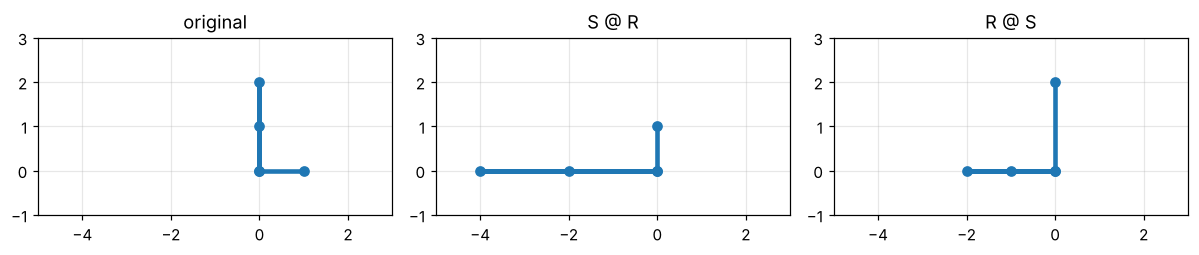

In [32]:
R = np.array([[0.0, -1.0], [1.0, 0.0]])       # rotación de 90°
S = np.array([[2.0, 0.0], [0.0, 1.0]])        # estira el eje horizontal

print("S @ R (primero rota, luego escala):\n", S @ R)
print("R @ S (primero escala, luego rota):\n", R @ S)
print("¿son iguales?", np.allclose(S @ R, R @ S))

# Una figura en forma de L, como filas de puntos
L = np.array([[0, 0], [0, 2], [0, 1], [0, 0], [1, 0]], dtype=float)
fig, axs = plt.subplots(1, 3, figsize=(11, 3.6))
for ax, (titulo, M) in zip(axs, [("original", np.eye(2)), ("S @ R", S @ R), ("R @ S", R @ S)]):
    P = L @ M.T
    ax.plot(*P.T, "o-", lw=3)
    ax.set_xlim(-5, 3); ax.set_ylim(-1, 3); ax.set_aspect("equal"); ax.set_title(titulo)
plt.tight_layout(); plt.show()

## 👀 Ejemplo 2 · Lotes, transpuesta y el colapso de dos capas lineales

In [33]:
rng = np.random.default_rng(4)
N, n, m = 5, 3, 2
X = rng.normal(size=(N, n))      # 5 datos como filas
W = rng.normal(size=(m, n))      # capa de 2 neuronas

Y = X @ W.T                      # (5, 3) @ (3, 2) -> (5, 2)
print("X:", X.shape, "| W:", W.shape, "| Y = X W^T:", Y.shape)
print("fila 0 de Y   :", Y[0])
print("W @ (dato 0)  :", W @ X[0], "  <- lo mismo")

A_ = rng.normal(size=(2, 3)); B_ = rng.normal(size=(3, 4))
print("\n(AB)^T == B^T A^T ?", np.allclose((A_ @ B_).T, B_.T @ A_.T))

# Dos capas lineales colapsan en una
W1 = rng.normal(size=(4, 3)); W2 = rng.normal(size=(2, 4))
x = rng.normal(size=3)
print("\nW2 (W1 x)  =", W2 @ (W1 @ x))
print("(W2 W1) x  =", (W2 @ W1) @ x, "  <- una sola capa de forma", (W2 @ W1).shape)

X: (5, 3) | W: (2, 3) | Y = X W^T: (5, 2)
fila 0 de Y   : [ 0.6995 -0.723 ]
W @ (dato 0)  : [ 0.6995 -0.723 ]   <- lo mismo

(AB)^T == B^T A^T ? True

W2 (W1 x)  = [1.7792 1.992 ]
(W2 W1) x  = [1.7792 1.992 ]   <- una sola capa de forma (2, 3)


#### ✏️ Ejercicio 7.1 · Las formas mandan

**Predecir formas.** Con $A$ de forma `(2, 3)` y $B$ de forma `(3, 4)`: (a) escribe la forma de `A @ B`; (b) decide si `B @ A` es posible (`True`/`False`). La celda lo comprueba ejecutándolo.

> ✅ **Resultado esperado:** `(2, 4)` y `False`: en `B @ A` las dimensiones interiores son $4$ y $2$, que no coinciden.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
A_ = np.ones((2, 3))
B_ = np.ones((3, 4))

forma_AB = ___
B_por_A_es_posible = ___

try:
    B_ @ A_
    posible_real = True
except ValueError:
    posible_real = False

print("forma real de A @ B:", (A_ @ B_).shape, "| ¿B @ A se puede?", posible_real)
verificar("predijiste la forma de A @ B", forma_AB == (A_ @ B_).shape)
verificar("predijiste si B @ A es posible", B_por_A_es_posible == posible_real)

#### ✏️ Ejercicio 7.2 · Lotes y transpuesta

**Un lote.** Calcula la salida de una capa $W\in\mathbb{R}^{2\times3}$ para 5 datos de dos maneras: $Y=XW^\top$ (datos como filas) y $Y_{\text{alt}}=WX^\top$ (datos como columnas). Comprueba que $Y_{\text{alt}}=Y^\top$, que es justo el teorema $(XW^\top)^\top=WX^\top$.

> ✅ **Resultado esperado:** Formas `(5, 2)` y `(2, 5)`, y tres ✅.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
rng = np.random.default_rng(5)
X = rng.normal(size=(5, 3))
W = rng.normal(size=(2, 3))

Y = ___
Y_alt = ___

print("Y:", Y.shape, "| Y_alt:", Y_alt.shape)
verificar("Y tiene forma (5, 2)", Y.shape == (5, 2))
verificar("cada fila de Y es W @ (un dato)", all(np.allclose(Y[i], W @ X[i]) for i in range(5)))
verificar("Y_alt = Y^T", np.allclose(Y_alt, Y.T))

#### ✏️ Ejercicio 7.3 · Dos capas lineales colapsan

**El cuello de botella.** Una red lineal va de $\mathbb{R}^5$ a una capa de **2** neuronas ($W_1\in\mathbb{R}^{2\times5}$) y de vuelta a $\mathbb{R}^5$ ($W_2\in\mathbb{R}^{5\times2}$). Calcula la matriz equivalente $W_{\text{eq}}=W_2W_1$, comprueba que da las mismas salidas que las dos capas y que su rango es solo $2$, aunque sea de $5\times5$.

> ✅ **Resultado esperado:** `W_eq` de $5\times5$ pero de rango $2$.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
rng = np.random.default_rng(6)
W1 = rng.normal(size=(2, 5))
W2 = rng.normal(size=(5, 2))
X = rng.normal(size=(10, 5))            # 10 datos

W_eq = ___
dos_capas = (X @ W1.T) @ W2.T
una_capa = ___

print("W_eq:", W_eq.shape, "| rango:", np.linalg.matrix_rank(W_eq))
verificar("W_eq tiene forma (5, 5)", W_eq.shape == (5, 5))
verificar("dos capas = una capa", np.allclose(dos_capas, una_capa))
verificar("rango 2: el cuello de botella limita", np.linalg.matrix_rank(W_eq) == 2)

---
# Concepto 8 · Núcleo, imagen y rango

> 🎯 **Objetivo.** Entender qué entradas una transformación **no puede ver** (su núcleo), qué salidas **puede producir** (su imagen) y el teorema que las relaciona. Con eso descubrimos el hecho más revelador del cuaderno: **una neurona en $\mathbb{R}^n$ es ciega a $n-1$ direcciones**.

## 💡 La historia

Piensa en tu sombra al mediodía. Si das un salto, tu sombra no cambia de forma: el movimiento vertical es **invisible** para el suelo. Toda la información de "altura" se pierde en la proyección. El **núcleo** de una transformación es exactamente eso: el conjunto de movimientos que **no producen ningún cambio** en la salida.

Una neurona de 784 entradas resume una imagen en **un solo número**. Es inevitable que pierda información, y el álgebra lineal nos dice cuánta: 783 dimensiones de información se vuelven invisibles para esa neurona. Por eso una red usa **muchas** neuronas, cada una mirando una dirección distinta.

## 📐 La matemática

Sea $A\in\mathbb{R}^{m\times n}$.

**Definición (núcleo).** $\ker A=\{\,x\in\mathbb{R}^n:\ Ax=0\,\}\subseteq\mathbb{R}^n$. Es un subespacio: si $Ax=0$ y $Ay=0$, entonces $A(\alpha x+\beta y)=\alpha Ax+\beta Ay=0$.

**Definición (imagen).** $\operatorname{im}A=\{\,Ax:\ x\in\mathbb{R}^n\,\}\subseteq\mathbb{R}^m$. Por la lectura por columnas es el **span de las columnas** de $A$, y su dimensión es el **rango**.

**Teorema (rango–nulidad).**

$$\dim\ker A+\operatorname{rango}A=n .$$

(Es un resultado estándar de todo curso de álgebra lineal; aquí lo usamos sin demostrarlo.) Se lee así: de las $n$ dimensiones de la entrada, unas sobreviven (las de la imagen) y las demás se pierden (las del núcleo).

**Teorema (estructura de las soluciones).** Si $x_p$ es una solución de $Ax=c$, todas las soluciones son

$$\{\,x_p+v:\ v\in\ker A\,\}.$$

*Demostración:* si $Ax=c$, entonces $A(x-x_p)=c-c=0$, así que $x-x_p\in\ker A$. Recíprocamente, $A(x_p+v)=c+0=c$. $\blacksquare$ Es decir, el conjunto de soluciones es el núcleo **trasladado**.

**Consecuencia.** $A$ es inyectiva (entradas distintas dan salidas distintas) si y solo si $\ker A=\{0\}$.

## 🧠 Conexión con la neurona

Una neurona es la matriz $1\times n$ $w^\top$, con $w\neq0$. Su rango es $1$, así que por rango–nulidad

$$\dim\ker(w^\top)=n-1,\qquad \ker(w^\top)=\{\,x:\ w^\top x=0\,\}=w^\perp .$$

El núcleo es el **hiperplano por el origen perpendicular a $w$**. Ahora parte cada entrada en dos piezas (concepto 5):

$$x=\underbrace{\frac{w^\top x}{w^\top w}\,w}_{x_\parallel}+\underbrace{\Big(x-\frac{w^\top x}{w^\top w}\,w\Big)}_{x_\perp\,\in\,\ker(w^\top)}\qquad\Longrightarrow\qquad w^\top x=w^\top x_\parallel .$$

**La neurona solo ve la sombra de $x$ sobre $w$.** Cualquier cambio de $x$ dentro de las otras $n-1$ direcciones le es invisible. Para una capa $W\in\mathbb{R}^{m\times n}$ con $m<n$, $\dim\ker W\geq n-m>0$: hay entradas distintas con **exactamente la misma salida**, y la entrada no se puede reconstruir.

Y el conjunto $\{x:\ w^\top x=-b\}$ es, por el segundo teorema, **el núcleo trasladado**: un hiperplano que no pasa por el origen. Esa es la frontera de la neurona (concepto 10).

## 🏷️ Estatus

- 📘 **Definición:** núcleo, imagen, rango.
- 🟦 **Teorema:** el núcleo es subespacio y la estructura de soluciones (demostrados); rango–nulidad (citado, sin demostración aquí).

## 🚀 Para qué sirve después

La "ceguera" de una neurona es, a veces, una **virtud**: en el ejemplo unificador verás un detector de bordes ciego a los cambios de iluminación. En robótica, el núcleo de la matriz jacobiana de un brazo indica los movimientos de las articulaciones que **no mueven** la punta (redundancia).

## 👀 Ejemplo 1 · Las direcciones invisibles de una neurona en $\mathbb{R}^3$

In [37]:
w = np.array([1.0, 2.0, 2.0])
W1 = w[None, :]                                  # la neurona como matriz (1, 3)
print("rango:", np.linalg.matrix_rank(W1), "-> dim del núcleo =", 3 - np.linalg.matrix_rank(W1))

# Desde cero: dos vectores perpendiculares a w, encontrados a mano
v1 = np.array([2.0, -1.0, 0.0])                  # 2 - 2 + 0 = 0
v2 = np.array([2.0, 0.0, -1.0])                  # 2 + 0 - 2 = 0
print("w·v1 =", w @ v1, "| w·v2 =", w @ v2, "| ¿independientes?", np.linalg.matrix_rank(np.column_stack([v1, v2])) == 2)

# Con librería: base ortonormal del núcleo
N_ = null_space(W1)
print("null_space(w):", N_.shape, "| w @ N =", w @ N_)

# Mover x dentro del núcleo no cambia la respuesta
x = np.array([1.0, 1.0, 1.0])
for desplazamiento in (0.0, 3.0 * v1, -2.0 * v1 + 5.0 * v2):
    print("w·(x + desplazamiento) =", w @ (x + desplazamiento))

rango: 1 -> dim del núcleo = 2
w·v1 = 0.0 | w·v2 = 0.0 | ¿independientes? True
null_space(w): (3, 2) | w @ N = [0. 0.]
w·(x + desplazamiento) = 5.0
w·(x + desplazamiento) = 5.0
w·(x + desplazamiento) = 5.0


## 👀 Ejemplo 2 · Una capa que pierde información, y una capa cuya imagen es una recta

rango: 2 | nulidad: 1
W @ k = [0. 0.]
entradas distintas: [2. 0. 1.] [ 6. -4.  5.] -> salidas iguales: [2. 1.] [2. 1.]


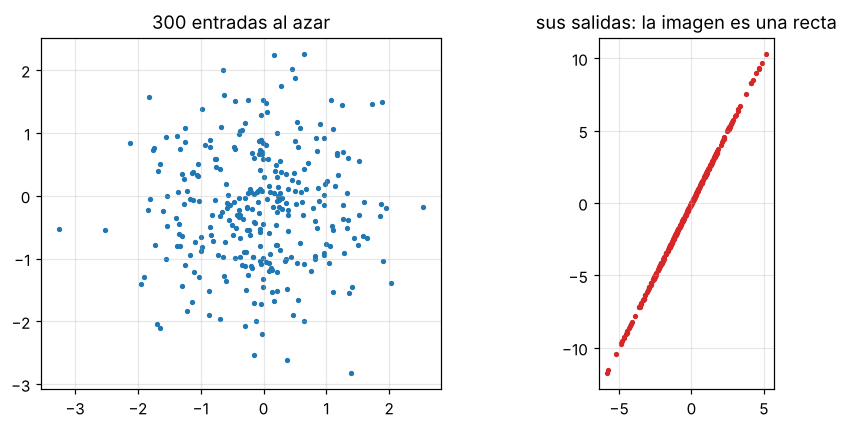

In [38]:
W = np.array([[1.0, 1.0, 0.0],
              [0.0, 1.0, 1.0]])                  # 2 neuronas, 3 entradas
print("rango:", np.linalg.matrix_rank(W), "| nulidad:", 3 - np.linalg.matrix_rank(W))
k = np.array([1.0, -1.0, 1.0])                   # está en el núcleo
print("W @ k =", W @ k)
xa = np.array([2.0, 0.0, 1.0]); xb = xa + 4 * k
print("entradas distintas:", xa, xb, "-> salidas iguales:", W @ xa, W @ xb)

# Una capa de rango 1: TODAS sus salidas caen sobre una recta (su imagen)
W_def = np.array([[1.0, 2.0],
                  [2.0, 4.0]])
rng = np.random.default_rng(7)
entradas = rng.normal(size=(300, 2))
salidas = entradas @ W_def.T
fig, axs = plt.subplots(1, 2, figsize=(9, 4))
axs[0].scatter(*entradas.T, s=6); axs[0].set_title("300 entradas al azar")
axs[1].scatter(*salidas.T, s=6, color="tab:red"); axs[1].set_title("sus salidas: la imagen es una recta")
for ax in axs: ax.set_aspect("equal")
plt.tight_layout(); plt.show()

#### ✏️ Ejercicio 8.1 · Rango + nulidad = n

**Rango–nulidad.** Para la matriz $M\in\mathbb{R}^{3\times5}$, calcula el rango y la nulidad $5-\text{rango}$, y compruébalo contando las columnas de `null_space(M)`.

> ✅ **Resultado esperado:** Rango $2$ y nulidad $3$: $2+3=5$.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
M = np.array([[1.0, 2.0, 0.0, 1.0, 0.0],
              [0.0, 0.0, 1.0, 1.0, 0.0],
              [1.0, 2.0, 1.0, 2.0, 0.0]])

rango = ___
nulidad = ___

print("rango =", rango, "| nulidad =", nulidad, "| columnas de null_space:", null_space(M).shape[1])
verificar("rango = 2 (la fila 3 es la suma de las otras dos)", rango == 2)
verificar("nulidad = 3", nulidad == 3)
verificar("coincide con null_space", null_space(M).shape[1] == nulidad)

#### ✏️ Ejercicio 8.2 · Lo que la neurona no ve

**Una dirección invisible.** Para la neurona $w=(2,-1,0)$, escribe un vector $v\neq0$ del núcleo y comprueba que mover $x$ en esa dirección no cambia la respuesta.

> 💡 **Pista:** Necesitas $2v_1-v_2=0$, y $v_3$ puede ser lo que quieras. Hay muchas respuestas válidas.

> ✅ **Resultado esperado:** Por ejemplo $v=(1,2,0)$ o $v=(0,0,1)$. Tres ✅.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
w = np.array([2.0, -1.0, 0.0])
v = np.array([___, ___, ___])
x = np.array([1.0, 1.0, 1.0])

print("w·v =", w @ v, "| w·x =", w @ x, "| w·(x + 5v) =", w @ (x + 5 * v))
verificar("v no es el vector cero", np.linalg.norm(v) > 0)
verificar("v está en el núcleo", np.isclose(w @ v, 0))
verificar("la respuesta no cambia", np.isclose(w @ (x + 5 * v), w @ x))

#### ✏️ Ejercicio 8.3 · Descomponer la entrada

**La neurona solo ve la sombra.** Con $w=(1,2,2)$ y $x=(3,0,3)$, descompón $x=x_\parallel+x_\perp$ (proyección sobre $w$ más resto) y comprueba que $w^\top x_\perp=0$ y que $w^\top x=w^\top x_\parallel$.

> ✅ **Resultado esperado:** $x_\parallel=(1,2,2)$, $x_\perp=(2,-2,1)$ y $w^\top x=9=w^\top x_\parallel$.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
w = np.array([1.0, 2.0, 2.0])
x = np.array([3.0, 0.0, 3.0])

x_par = ___
x_perp = ___

print("x_par =", x_par, "| x_perp =", x_perp)
verificar("x_par = (1, 2, 2) y x_perp = (2, -2, 1)", np.allclose(x_par, [1, 2, 2]) and np.allclose(x_perp, [2, -2, 1]))
verificar("x_perp está en el núcleo de la neurona", np.isclose(w @ x_perp, 0))
verificar("la neurona responde igual a x y a su sombra", np.isclose(w @ x, w @ x_par))

---
# Concepto 9 · Transformaciones afines, sesgo y coordenadas homogéneas

> 🎯 **Objetivo.** Entender que la neurona no es lineal sino **afín** (por el sesgo), demostrar que las capas afines apiladas también colapsan y aprender el **truco de las coordenadas homogéneas**: el sesgo es simplemente un peso más, conectado a una entrada que siempre vale $1$. El mismo truco mueve los robots.

## 💡 La historia

Un termómetro marca en Celsius y quieres Fahrenheit: $F=1.8\,C+32$. Ese $+32$ arruina la linealidad, porque $0\,^\circ$C no va a $0\,^\circ$F. Pero hay un truco de contabilidad: si escribes cada temperatura como el par $(C,\,1)$, entonces

$$F=1.8\cdot C+32\cdot1=(1.8,\ 32)\cdot(C,\ 1),$$

y la conversión vuelve a ser **un producto punto**, es decir, lineal, pero en una dimensión más. Agregar un "1" al final de cada vector convierte lo **afín** en **lineal**. Los ingenieros de robótica usan exactamente este truco para encadenar rotaciones y traslaciones de las articulaciones de un brazo.

## 📐 La matemática

**Definición (transformación afín).** $G:\mathbb{R}^n\to\mathbb{R}^m$, $G(x)=Ax+c$, con $A\in\mathbb{R}^{m\times n}$ y $c\in\mathbb{R}^m$. Es lineal solo si $c=0$, porque $G(0)=c$.

**Teorema (la composición de afines es afín).** Si $G_1(x)=A_1x+c_1$ y $G_2(y)=A_2y+c_2$, entonces

$$G_2\big(G_1(x)\big)=A_2(A_1x+c_1)+c_2=(A_2A_1)\,x+(A_2c_1+c_2).\qquad\blacksquare$$

**Consecuencia para las redes.** Dos capas **con sesgo** pero **sin activación** también colapsan:

$$W_2(W_1x+b_1)+b_2=\underbrace{(W_2W_1)}_{W_{\text{eq}}}\,x+\underbrace{(W_2b_1+b_2)}_{b_{\text{eq}}} .$$

Con esto queda claro qué aporta la activación $f$: **es lo único que impide este colapso**.

**Coordenadas homogéneas.** Agrega un $1$ al final: $\tilde x=\begin{pmatrix}x\\1\end{pmatrix}\in\mathbb{R}^{n+1}$. Con la matriz por bloques

$$\tilde A=\begin{pmatrix}A&c\\0^\top&1\end{pmatrix}\in\mathbb{R}^{(m+1)\times(n+1)},\qquad \tilde A\tilde x=\begin{pmatrix}Ax+c\cdot1\\0^\top x+1\cdot1\end{pmatrix}=\begin{pmatrix}Ax+c\\1\end{pmatrix}.$$

La transformación afín se volvió **una multiplicación de matrices**, y componer afines es **multiplicar** sus $\tilde A$.

**Para una neurona** basta la primera parte: con $\tilde w=\begin{pmatrix}w\\b\end{pmatrix}\in\mathbb{R}^{n+1}$,

$$\tilde w^\top\tilde x=w^\top x+b\cdot1=w^\top x+b .$$

Para un lote, se agrega una **columna de unos**: $\tilde X=[\,X\mid\mathbf 1\,]\in\mathbb{R}^{N\times(n+1)}$ y $\tilde X\tilde w=Xw+b\mathbf 1$. Para una capa, $\tilde W=[\,W\mid b\,]\in\mathbb{R}^{m\times(n+1)}$.

**Lectura geométrica.** El hiperplano afín $\{x:\ w^\top x+b=0\}$ de $\mathbb{R}^n$ es la intersección del hiperplano **por el origen** $\ker(\tilde w^\top)\subset\mathbb{R}^{n+1}$ con la "rebanada" donde la última coordenada vale $1$.

## 🧠 Conexión con la neurona

**El sesgo $b$ es un peso más**, conectado a una entrada ficticia que siempre vale $1$. Con este truco, todo lo que demostramos para funciones lineales (núcleos, proyecciones, mínimos cuadrados) se aplica de inmediato a la neurona con sesgo. Lo usaremos en el proyecto para entrenar $w$ y $b$ **juntos** con una sola proyección.

## 🏷️ Estatus

- 📘 **Definición:** transformación afín, coordenadas homogéneas.
- 🟦 **Teorema:** composición de afines es afín; la identidad por bloques (demostrados arriba).
- 🟧 **Práctica:** las librerías (PyTorch, por ejemplo) guardan $b$ por separado de $W$; el truco es la forma de **pensarlo**, y a veces de calcularlo.

## 🚀 Para qué sirve después

En robótica, la posición y orientación de un cuerpo rígido en 3D se representa con matrices homogéneas de $4\times4$, $\begin{pmatrix}R&t\\0^\top&1\end{pmatrix}$, donde $R$ es una rotación y $t$ una traslación. La cinemática directa de un brazo es **el producto** de las matrices de sus articulaciones.

## 👀 Ejemplo 1 · Un movimiento rígido en 2D, directo y con coordenadas homogéneas

T =
 [[ 0.866 -0.5    2.   ]
 [ 0.5    0.866  1.   ]
 [ 0.     0.     1.   ]]
¿coinciden? True


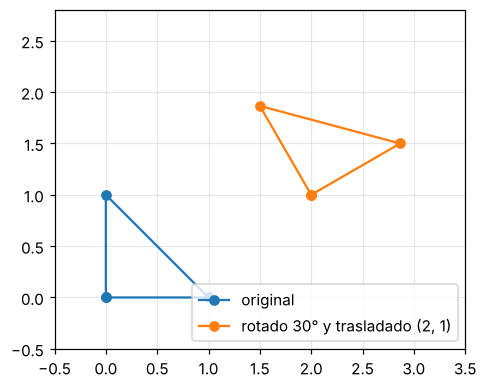

In [42]:
phi = np.radians(30)
R = np.array([[np.cos(phi), -np.sin(phi)], [np.sin(phi), np.cos(phi)]])
t = np.array([2.0, 1.0])

T = np.eye(3)                     # matriz homogénea 3x3
T[:2, :2] = R
T[:2, 2] = t
print("T =\n", T)

triangulo = np.array([[0, 0], [1, 0], [0, 1], [0, 0]], dtype=float)      # (4, 2)
directo = triangulo @ R.T + t                                             # R x + t para cada fila
tri_h = np.column_stack([triangulo, np.ones(len(triangulo))])             # (4, 3): agregar el 1
homogeneo = (tri_h @ T.T)[:, :2]
print("¿coinciden?", np.allclose(directo, homogeneo))

fig, ax = plt.subplots(figsize=(5, 4))
ax.plot(*triangulo.T, "o-", label="original")
ax.plot(*homogeneo.T, "o-", label="rotado 30° y trasladado (2, 1)")
ax.set_aspect("equal"); ax.legend(loc="lower right"); ax.set_xlim(-0.5, 3.5); ax.set_ylim(-0.5, 2.8)
plt.show()

## 👀 Ejemplo 2 · El truco del sesgo en una neurona y en un lote, y el colapso de dos capas afines

In [43]:
w = np.array([0.5, -1.0]); b = 0.3
x = np.array([2.0, 1.0])
print("w·x + b                   =", w @ x + b)
x_aug = np.append(x, 1.0); w_aug = np.append(w, b)
print("w_aug·x_aug (homogéneas)  =", w_aug @ x_aug, "| formas:", x_aug.shape, w_aug.shape)

X = np.array([[2.0, 1.0], [0.0, 0.0], [-1.0, 2.0]])          # (3, 2)
X_aug = np.column_stack([X, np.ones(len(X))])                # (3, 3)
print("\nX w + b       :", X @ w + b)
print("X_aug @ w_aug :", X_aug @ w_aug)

rng = np.random.default_rng(8)
W1, b1 = rng.normal(size=(4, 2)), rng.normal(size=4)
W2, b2 = rng.normal(size=(1, 4)), rng.normal(size=1)
dos_capas = (X @ W1.T + b1) @ W2.T + b2
W_eq, b_eq = W2 @ W1, W2 @ b1 + b2
print("\ndos capas afines:", dos_capas.ravel())
print("una capa afín   :", (X @ W_eq.T + b_eq).ravel(), "  <- colapsaron")

w·x + b                   = 0.3
w_aug·x_aug (homogéneas)  = 0.3 | formas: (3,) (3,)

X w + b       : [ 0.3  0.3 -2.2]
X_aug @ w_aug : [ 0.3  0.3 -2.2]

dos capas afines: [-3.9005  2.3421  2.939 ]
una capa afín   : [-3.9005  2.3421  2.939 ]   <- colapsaron


#### ✏️ Ejercicio 9.1 · El sesgo como un peso más

**Tu ejemplo de siempre, con el truco.** Con $x=(2,1)$, $w=(0.5,-1)$ y $b=0.3$, construye $\tilde x$ y $\tilde w$ con `np.append` y comprueba que $\tilde w^\top\tilde x=w^\top x+b=0.3$.

> ✅ **Resultado esperado:** $\tilde x=(2,1,1)$, $\tilde w=(0.5,-1,0.3)$ y producto $0.3$.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
x = np.array([2.0, 1.0])
w = np.array([0.5, -1.0])
b = 0.3

x_aug = ___
w_aug = ___

print("x_aug =", x_aug, "| w_aug =", w_aug, "| producto =", w_aug @ x_aug)
verificar("formas (3,)", x_aug.shape == (3,) and w_aug.shape == (3,))
verificar("w_aug·x_aug = 0.3", np.isclose(w_aug @ x_aug, 0.3))
verificar("igual a w·x + b", np.isclose(w_aug @ x_aug, w @ x + b))

#### ✏️ Ejercicio 9.2 · Una capa en coordenadas homogéneas

**Una capa con el truco.** Con $W\in\mathbb{R}^{3\times2}$, $b\in\mathbb{R}^3$ y 4 datos $X\in\mathbb{R}^{4\times2}$: construye $\tilde X=[X\mid\mathbf 1]$ y $\tilde W=[W\mid b]$ con `np.column_stack`, y comprueba que $\tilde X\tilde W^\top=XW^\top+b$.

> ✅ **Resultado esperado:** Formas `(4, 3)` y `(3, 3)`, y tres ✅.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
rng = np.random.default_rng(9)
W = rng.normal(size=(3, 2))
b = np.array([0.5, -1.0, 2.0])
X = rng.normal(size=(4, 2))

X_aug = ___
W_aug = ___

print("X_aug:", X_aug.shape, "| W_aug:", W_aug.shape)
verificar("X_aug tiene forma (4, 3)", X_aug.shape == (4, 3))
verificar("W_aug tiene forma (3, 3)", W_aug.shape == (3, 3))
verificar("X_aug W_aug^T = X W^T + b", np.allclose(X_aug @ W_aug.T, X @ W.T + b))

#### ✏️ Ejercicio 9.3 · Encadenar movimientos de un robot

**Robótica: encadenar movimientos.** $T_1$ rota $90^\circ$ y $T_2$ traslada $(3,1)$, ambas en homogéneas $3\times3$. Calcula la matriz del movimiento compuesto "primero $T_1$, luego $T_2$" y aplícala al punto $p=(1,0)$, escrito como $\tilde p=(1,0,1)$. Después observa qué pasa si inviertes el orden.

> 💡 **Pista:** La matriz que actúa **primero** va a la **derecha**: $T_2T_1\tilde p=T_2(T_1\tilde p)$.

> ✅ **Resultado esperado:** $(3,2,1)$. En el otro orden el punto llega a $(-1,4)$.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
T1 = np.array([[0.0, -1.0, 0.0],
               [1.0,  0.0, 0.0],
               [0.0,  0.0, 1.0]])          # rotación 90°
T2 = np.array([[1.0, 0.0, 3.0],
               [0.0, 1.0, 1.0],
               [0.0, 0.0, 1.0]])           # traslación (3, 1)
p_h = np.array([1.0, 0.0, 1.0])

T = ___
resultado = ___

print("primero rota, luego traslada:", resultado)
print("primero traslada, luego rota:", T1 @ T2 @ p_h)
verificar("el punto llega a (3, 2)", np.allclose(resultado, [3, 2, 1]))
verificar("aplicar T es lo mismo que aplicar T1 y luego T2", np.allclose(resultado, T2 @ (T1 @ p_h)))
verificar("el orden importa", not np.allclose(T2 @ T1, T1 @ T2))

---
# Concepto 10 · Hiperplanos, semiespacios y distancia

> 🎯 **Objetivo.** Juntar todo lo anterior para entender la **frontera de decisión** de una neurona: el hiperplano $w^\top x+b=0$. Demostraremos que es un núcleo trasladado de dimensión $n-1$, que $w$ es perpendicular a él y que $\dfrac{w^\top x+b}{\lVert w\rVert}$ es la **distancia con signo** de $x$ a la frontera.

## 💡 La historia

Todos los capítulos anteriores fueron preparando este. La neurona toma un punto $x$ de $\mathbb{R}^n$ (concepto 1), lo compara con su patrón $w$ (concepto 4), es ciega a todo lo perpendicular a $w$ (concepto 8) y se desplaza con el sesgo $b$ (concepto 9). Junta esas piezas y obtienes una imagen muy simple: **una pared plana** que parte el espacio en dos mitades. La neurona responde una sola pregunta sobre cada punto: *¿de qué lado de la pared estás, y qué tan lejos?*

## 📐 La matemática

**Definición (hiperplano).** Para $w\in\mathbb{R}^n$, $w\neq0$, y $b\in\mathbb{R}$:

$$H=\{\,x\in\mathbb{R}^n:\ w^\top x+b=0\,\}.$$

**Teorema (estructura).** $H=x_0+\ker(w^\top)$ para cualquier $x_0\in H$, así que $H$ es un subespacio afín de dimensión $n-1$.

*Demostración.* $H$ es el conjunto de soluciones de $w^\top x=-b$. Por el teorema de estructura de soluciones (concepto 8), $H=x_0+\ker(w^\top)$, y por rango–nulidad $\dim\ker(w^\top)=n-1$. Un punto concreto de $H$ es

$$x_0=-\frac{b}{w^\top w}\,w,\qquad\text{pues}\quad w^\top x_0+b=-\frac{b\,w^\top w}{w^\top w}+b=0 .\qquad\blacksquare$$

**Corolario ($w$ es normal a $H$).** Si $x_1,x_2\in H$, entonces $x_1-x_2\in\ker(w^\top)$, es decir, $w^\top(x_1-x_2)=0$. Toda dirección **dentro** de la pared es perpendicular a $w$.

**Semiespacios.** Con $s(x)=w^\top x+b$: $H^+=\{s>0\}$ (el lado hacia donde apunta $w$), $H^-=\{s<0\}$ y la pared $\{s=0\}$.

**Teorema (distancia con signo).** La distancia con signo de $x$ a $H$ es

$$t(x)=\frac{w^\top x+b}{\lVert w\rVert}.$$

*Demostración por proyección (concepto 5).* La distancia de $x$ a $H$ es la longitud de la sombra de $x-x_0$ sobre la dirección normal unitaria $\hat w$ (la parte de $x-x_0$ dentro de la pared no acerca ni aleja). Esa sombra con signo es

$$t=(x-x_0)\cdot\hat w=\frac{w^\top x-w^\top x_0}{\lVert w\rVert}=\frac{w^\top x-(-b)}{\lVert w\rVert}=\frac{w^\top x+b}{\lVert w\rVert}.\qquad\blacksquare$$

El **punto de $H$ más cercano** a $x$ es $x_p=x-t\,\hat w$, y la distancia de $H$ al origen es

$$\lvert t(0)\rvert=\frac{\lvert b\rvert}{\lVert w\rVert}.$$

**Escala.** Para $c\neq0$, $(cw,\,cb)$ define **el mismo** hiperplano (la ecuación solo se multiplicó por $c$). La distancia con signo se multiplica por el signo de $c$: si $c<0$, los lados se intercambian.

**Curvas de nivel.** Los conjuntos $\{x:\ s(x)=k\}$, para cada $k\in\mathbb{R}$, son hiperplanos **paralelos** a $H$ (misma normal $w$).

## 🧠 Conexión con la neurona

Todo queda en una línea:

$$z=f\big(w^\top x+b\big)=f\big(\lVert w\rVert\cdot t(x)\big).$$

La parte lineal de la neurona mide la **distancia con signo a su pared**, escalada por $\lVert w\rVert$, y la activación $f$ convierte ese número en una decisión. Si $f$ es el escalón o la sigmoide, "$z\geq0.5$" equivale a "$x$ está en $H^+$". **Clasificar es decidir de qué lado de un hiperplano cae un punto.**

## 🏷️ Estatus

- 📘 **Definición:** hiperplano, semiespacios.
- 🟦 **Teorema:** estructura y dimensión, normalidad de $w$, distancia con signo, invariancia por escala (demostrados arriba).
- 🟨 **Heurística:** leer $\lVert w\rVert$ como "seguridad" de la neurona depende de la activación; no es un resultado general.

## 🚀 Para qué sirve después

Las máquinas de soporte vectorial (SVM) eligen el hiperplano que **maximiza** esta distancia a los datos. En una red profunda, cada neurona de la primera capa es una pared en el espacio de entrada, y las capas siguientes combinan esas paredes para formar regiones complicadas.

## 👀 Ejemplo 1 · Una recta en $\mathbb{R}^2$: normal, lados, distancia y punto más cercano

distancia con signo de x: 1.7888543819998317
punto más cercano x_p: [2.2 0.4] -> s(x_p) = 4.440892098500626e-16
punto de H más cercano al origen x0: [0.6 1.2] | distancia al origen |b|/||w|| = 1.3416407864998738


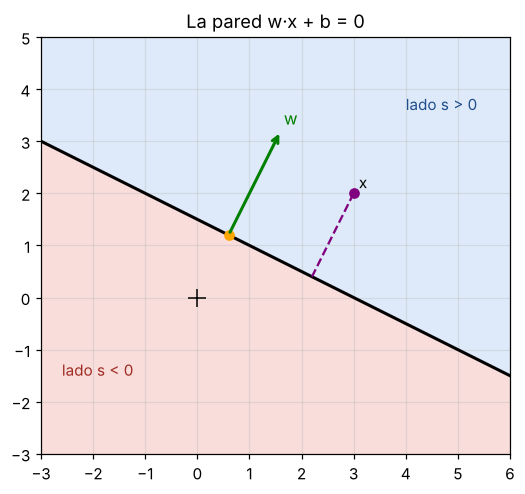

In [47]:
w = np.array([1.0, 2.0]); b = -3.0
nw = np.linalg.norm(w)
x = np.array([3.0, 2.0])

t = (w @ x + b) / nw
x_p = x - t * w / nw
x0 = -b / (w @ w) * w
print("distancia con signo de x:", t)
print("punto más cercano x_p:", x_p, "-> s(x_p) =", w @ x_p + b)
print("punto de H más cercano al origen x0:", x0, "| distancia al origen |b|/||w|| =", abs(b) / nw)

g = np.linspace(-3, 6, 300)
G1, G2 = np.meshgrid(g, g)
S = w[0] * G1 + w[1] * G2 + b
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.contourf(G1, G2, np.sign(S), levels=[-2, 0, 2], colors=["#f4c7c3", "#c9dcf5"], alpha=0.6)
ax.plot(g, -(w[0] * g + b) / w[1], "k", lw=2)
flecha(ax, w, origen=x0, color="green", texto="w")
ax.plot(*x, "o", color="purple"); ax.text(x[0] + 0.1, x[1] + 0.1, "x")
ax.plot([x[0], x_p[0]], [x[1], x_p[1]], "--", color="purple")
ax.plot(0, 0, "k+", ms=12); ax.plot(*x0, "o", color="orange")
ax.text(4, 3.6, "lado s > 0", color="#1f4e8c"); ax.text(-2.6, -1.5, "lado s < 0", color="#a02b22")
ax.set_xlim(-3, 6); ax.set_ylim(-3, 5); ax.set_aspect("equal")
ax.set_title("La pared w·x + b = 0")
plt.show()

## 👀 Ejemplo 2 · Un plano en $\mathbb{R}^3$: construido como núcleo trasladado

Generamos puntos de $H$ como $x_0+Nc$, donde las columnas de $N$ son una base del núcleo de $w^\top$. Luego comprobamos la fórmula de la distancia contra una búsqueda a ciegas sobre esos puntos.

In [48]:
w = np.array([1.0, 2.0, 2.0]); b = -6.0
x0 = -b / (w @ w) * w
N_ = null_space(w[None, :])                      # (3, 2): base del núcleo
rng = np.random.default_rng(10)
coefs = rng.uniform(-10, 10, size=(200000, 2))
puntos_H = x0 + coefs @ N_.T                     # (200000, 3), todos en H
print("máximo |w·x + b| en los puntos de H:", np.max(np.abs(puntos_H @ w + b)))

x = np.array([4.0, 1.0, 3.0])
t = (w @ x + b) / np.linalg.norm(w)
print("distancia con signo (fórmula):", t)
print("distancia mínima (a ciegas)  :", np.min(np.linalg.norm(puntos_H - x, axis=1)))

# Un lote: lados y distancias de varios puntos a la vez
X = np.array([[0.0, 0.0, 0.0], [2.0, 1.0, 0.5], [4.0, 1.0, 3.0], [-1.0, -1.0, -1.0]])
print("\ndistancias con signo del lote:", (X @ w + b) / np.linalg.norm(w))

máximo |w·x + b| en los puntos de H: 5.329070518200751e-15
distancia con signo (fórmula): 2.0
distancia mínima (a ciegas)  : 2.000311236573401

distancias con signo del lote: [-2.     -0.3333  2.     -3.6667]


#### ✏️ Ejercicio 10.1 · Distancia con signo

Con $w=(3,4)$, $b=-10$, calcula la distancia con signo del origen a la recta. ¿De qué lado queda?

> ✅ **Resultado esperado:** $t=-2$: el origen está a 2 unidades, en el lado negativo.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
w = np.array([3.0, 4.0])
b = -10.0
x = np.array([0.0, 0.0])

t = ___

print("t =", t)
verificar("t = -2", np.isclose(t, -2))
verificar("el origen está en el lado negativo", t < 0)

#### ✏️ Ejercicio 10.2 · El punto más cercano

Con la misma recta y $x=(5,5)$, calcula $t$ y el punto más cercano $x_p=x-t\,\hat w$. Comprueba que $x_p$ está sobre la recta.

> ✅ **Resultado esperado:** $t=5$ y $x_p=(2,1)$.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
w = np.array([3.0, 4.0])
b = -10.0
x = np.array([5.0, 5.0])

t = (w @ x + b) / np.linalg.norm(w)
x_p = ___

print("t =", t, "| x_p =", x_p)
verificar("t = 5", np.isclose(t, 5))
verificar("x_p = (2, 1)", np.allclose(x_p, [2, 1]))
verificar("x_p está sobre la recta", np.isclose(w @ x_p + b, 0))

#### ✏️ Ejercicio 10.3 · Escalar w y b

**Misma pared, lados intercambiados.** Multiplica $(w,b)=((3,4),-10)$ por $c=-2$. Comprueba que los puntos $(2,1)$ y $(-2,4)$ siguen sobre la pared, y que la distancia con signo de $(5,5)$ **cambia de signo** pero no de tamaño.

> ✅ **Resultado esperado:** $t=5$ y $t_2=-5$.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
w = np.array([3.0, 4.0]); b = -10.0
w2 = -2 * w; b2 = -2 * b
x = np.array([5.0, 5.0])

t = (w @ x + b) / np.linalg.norm(w)
t2 = ___

en_H = [bool(np.isclose(w2 @ p + b2, 0)) for p in (np.array([2.0, 1.0]), np.array([-2.0, 4.0]))]
print("t =", t, "| t2 =", t2, "| ¿los puntos siguen en la pared?", en_H)
verificar("la pared es la misma", all(en_H))
verificar("la distancia cambió de signo pero no de tamaño", np.isclose(t2, -t))

---
# 🏁 Ejemplo unificador: una neurona que detecta bordes, con los 10 conceptos

> 🎯 **Objetivo.** Ver los 10 conceptos trabajando juntos en un problema real de visión por computador, en miniatura: una neurona que decide si un parche de imagen de $2\times2$ píxeles contiene un **borde vertical** (oscuro a la izquierda, claro a la derecha). Aquí solo ejecutas y observas. En el proyecto, después, lo construyes tú.

## 📖 La historia

La cámara de un robot que sigue líneas en el piso necesita detectar dónde cambia el color de oscuro a claro. El primer paso de casi cualquier sistema de visión es detectar **bordes**, y los parches pequeños son el lugar ideal para entender cómo lo hace una neurona.

Un parche de $2\times2$ tiene 4 píxeles con brillos entre $0$ (negro) y $1$ (blanco). Aplanado, es un vector de $\mathbb{R}^4$. Vamos a usar cuatro **patrones** especiales de $2\times2$, que serán la columna vertebral del ejemplo:

$$C=\begin{pmatrix}1&1\\1&1\end{pmatrix},\quad V=\begin{pmatrix}-1&1\\-1&1\end{pmatrix},\quad H=\begin{pmatrix}-1&-1\\1&1\end{pmatrix},\quad D=\begin{pmatrix}1&-1\\-1&1\end{pmatrix}.$$

Son, respectivamente, **constante** (brillo general), **borde vertical**, **borde horizontal** y **tablero**. La neurona tendrá como pesos el patrón $V$.

| Paso | Qué hacemos | Concepto |
|---|---|---|
| 1 | Los parches como vectores de $\mathbb{R}^4$ | 1 |
| 2 | Un parche como mezcla de los 4 patrones | 2 |
| 3 | Los patrones forman una base | 3 |
| 4 | La neurona compara con su plantilla | 4 |
| 5 | Los patrones son ortogonales: coordenadas por proyección | 5 |
| 6 | Una capa de 4 neuronas es una matriz | 6 |
| 7 | Un lote entero, y deshacer la transformación | 7 |
| 8 | Lo que la neurona no ve: ¡la iluminación! | 8 |
| 9 | El sesgo como umbral, en coordenadas homogéneas | 9 |
| 10 | La pared en $\mathbb{R}^4$ y la decisión final | 10 |

## Paso 1 · Los datos: parches como vectores (concepto 1)

Generamos 200 parches: 100 con borde vertical y 100 "otros" (constantes con distinta iluminación, bordes horizontales, bordes invertidos y texturas sin borde). Los guardamos con forma `(200, 2, 2)` y los aplanamos a `(200, 4)`: **cada fila es un punto de $\mathbb{R}^4$**.

parches: (200, 2, 2) -> P: (200, 4)


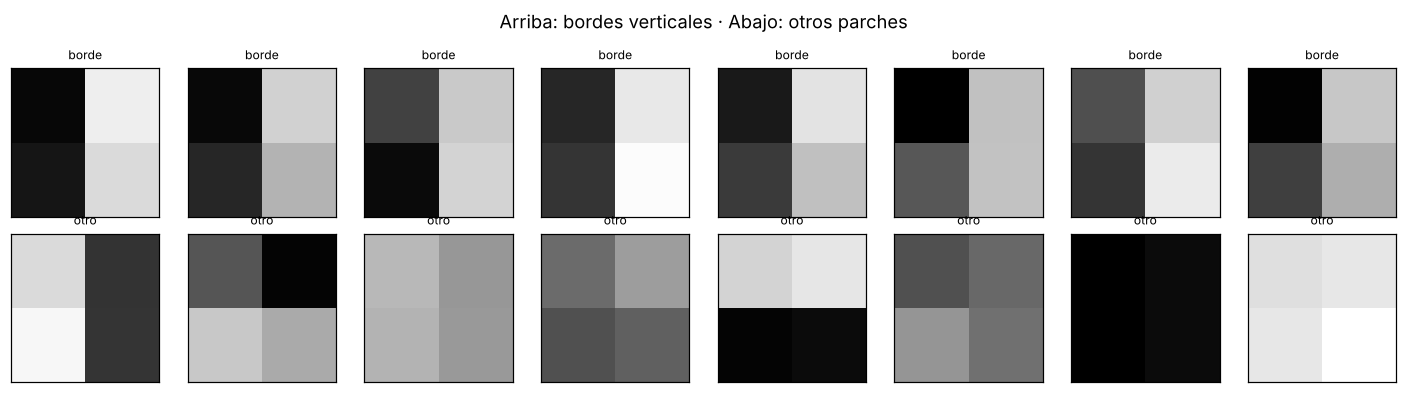

In [52]:
patrones = {
    "constante C":        np.array([[1, 1], [1, 1]], dtype=float),
    "borde vertical V":   np.array([[-1, 1], [-1, 1]], dtype=float),
    "borde horizontal H": np.array([[-1, -1], [1, 1]], dtype=float),
    "tablero D":          np.array([[1, -1], [-1, 1]], dtype=float),
}
C_, V_, H_, D_ = (p.flatten() for p in patrones.values())      # vectores de R^4

rng = np.random.default_rng(3)

def parche_borde_vertical():
    izq = rng.uniform(0.0, 0.35, size=2)
    der = rng.uniform(0.65, 1.0, size=2)
    return np.array([[izq[0], der[0]], [izq[1], der[1]]])

def parche_otro():
    tipo = rng.integers(4)
    if tipo == 0:                                   # constante, con distinta iluminación
        return np.full((2, 2), rng.uniform(0, 1)) + rng.normal(0, 0.05, (2, 2))
    if tipo == 1:                                   # borde horizontal
        a = rng.uniform(0, 0.35, 2); c = rng.uniform(0.65, 1, 2)
        return np.array([a, c]) if rng.random() < 0.5 else np.array([c, a])
    if tipo == 2:                                   # borde vertical invertido
        return parche_borde_vertical()[:, ::-1]
    return rng.uniform(0.3, 0.7, (2, 2))            # textura sin borde

N = 200
parches = np.array([parche_borde_vertical() for _ in range(N // 2)] +
                   [parche_otro() for _ in range(N // 2)])          # (200, 2, 2)
es_borde = np.array([1] * (N // 2) + [0] * (N // 2))                # etiquetas
P = parches.reshape(N, 4)                                           # (200, 4)
print("parches:", parches.shape, "-> P:", P.shape)

fig, axs = plt.subplots(2, 8, figsize=(13, 3.6))
for k, ax in enumerate(axs.ravel()):
    i = k if k < 8 else N // 2 + k
    ax.imshow(parches[i], cmap="gray", vmin=0, vmax=1)
    ax.set_title("borde" if es_borde[i] else "otro", fontsize=8)
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.suptitle("Arriba: bordes verticales · Abajo: otros parches")
plt.tight_layout(); plt.show()

## Paso 2 · Un parche es una mezcla de los 4 patrones (concepto 2)

Cualquier parche $p\in\mathbb{R}^4$ se puede escribir como

$$p=c_1\,C+c_2\,V+c_3\,H+c_4\,D .$$

Los coeficientes tienen significado: $c_1$ es el **brillo promedio**, $c_2$ la **fuerza del borde vertical**, $c_3$ la del **horizontal** y $c_4$ la del **tablero**. Los encontramos resolviendo un sistema cuyas columnas son los patrones.

parche p = [0.03   0.9304 0.0829 0.8538]
coeficientes (C, V, H, D) = [ 0.4743  0.4178 -0.0059 -0.0324]
reconstrucción B @ coef  = [0.03   0.9304 0.0829 0.8538]


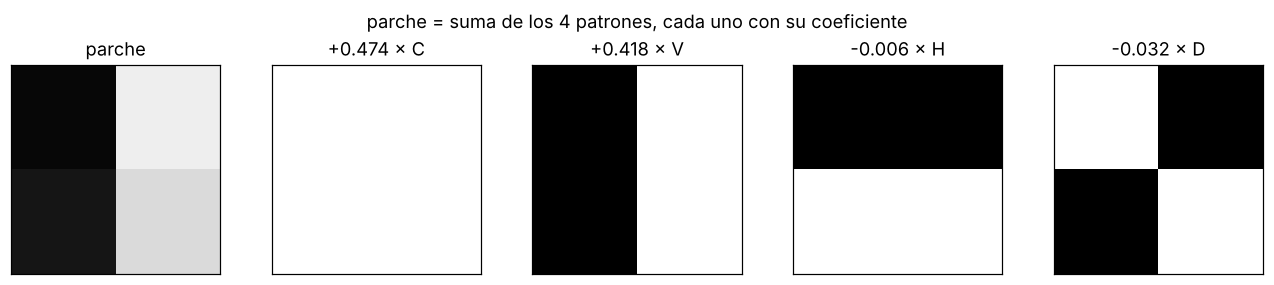

In [53]:
B = np.column_stack([C_, V_, H_, D_])           # (4, 4): los patrones como columnas
p = P[0]
coef = np.linalg.solve(B, p)
print("parche p =", p)
print("coeficientes (C, V, H, D) =", coef)
print("reconstrucción B @ coef  =", B @ coef)

fig, axs = plt.subplots(1, 5, figsize=(12, 2.6))
axs[0].imshow(p.reshape(2, 2), cmap="gray", vmin=0, vmax=1); axs[0].set_title("parche")
for ax, (nombre, pat), c in zip(axs[1:], patrones.items(), coef):
    ax.imshow(pat, cmap="gray", vmin=-1, vmax=1); ax.set_title(f"{c:+.3f} × {nombre.split()[-1]}")
for ax in axs:
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
plt.suptitle("parche = suma de los 4 patrones, cada uno con su coeficiente")
plt.tight_layout(); plt.show()

## Paso 3 · Los patrones forman una base de $\mathbb{R}^4$ (concepto 3)

Para que esa descomposición exista **y sea única** para cualquier parche, los 4 patrones deben ser linealmente independientes. Como son 4 vectores en $\mathbb{R}^4$, eso los convierte en una **base**.

In [54]:
print("rango de B:", np.linalg.matrix_rank(B), "de 4 -> los patrones son una base de R^4")

# Unicidad: los coeficientes de todos los parches a la vez, y la reconstrucción exacta
COEF = np.linalg.solve(B, P.T).T                 # (200, 4)
print("¿todos los parches se reconstruyen exactamente?", np.allclose(COEF @ B.T, P))

rango de B: 4 de 4 -> los patrones son una base de R^4
¿todos los parches se reconstruyen exactamente? True


## Paso 4 · La neurona compara cada parche con su plantilla (concepto 4)

La neurona tiene pesos $w=V$. Su respuesta lineal es $w^\top p$: grande y positiva si el parche se parece a un borde vertical, negativa si es un borde invertido, cercana a cero si no tiene borde vertical.

In [55]:
w = V_.copy()
respuestas = P @ w                               # (200,)
print("respuesta media en bordes verticales:", respuestas[es_borde == 1].mean())
print("respuesta media en otros parches     :", respuestas[es_borde == 0].mean())

cos = respuestas / (np.linalg.norm(w) * np.linalg.norm(P, axis=1))
print("similitud de coseno media en bordes  :", cos[es_borde == 1].mean())
print("similitud de coseno media en otros   :", cos[es_borde == 0].mean())

respuesta media en bordes verticales: 1.3162222015726435
respuesta media en otros parches     : -0.31722959914935706
similitud de coseno media en bordes  : 0.5412133308024739
similitud de coseno media en otros   : -0.12312134612014544


## Paso 5 · Los patrones son ortogonales: coordenadas sin resolver sistemas (concepto 5)

Aquí aparece una sorpresa agradable. Los 4 patrones son **mutuamente perpendiculares**: la matriz de todos sus productos punto (la **matriz de Gram** $B^\top B$) es diagonal. Cuando la base es ortogonal, el coeficiente de cada patrón es simplemente **la proyección** sobre él,

$$c_k=\frac{p\cdot u_k}{u_k\cdot u_k},$$

sin resolver ningún sistema. Y como $u_k\cdot u_k=4$ para los cuatro, el coeficiente del borde vertical es **la respuesta de la neurona dividida entre 4**.

In [56]:
print("matriz de Gram B^T B =\n", B.T @ B)

coef_por_proyeccion = np.array([(p @ u) / (u @ u) for u in (C_, V_, H_, D_)])
print("\ncoeficientes por proyección:", coef_por_proyeccion)
print("coeficientes por solve     :", coef)
print("respuesta de la neurona / 4:", (w @ p) / 4, "= coeficiente de V")

matriz de Gram B^T B =
 [[4. 0. 0. 0.]
 [0. 4. 0. 0.]
 [0. 0. 4. 0.]
 [0. 0. 0. 4.]]

coeficientes por proyección: [ 0.4743  0.4178 -0.0059 -0.0324]
coeficientes por solve     : [ 0.4743  0.4178 -0.0059 -0.0324]
respuesta de la neurona / 4: 0.417835472408966 = coeficiente de V


## Paso 6 · Una capa de 4 neuronas es una matriz (concepto 6)

Si ponemos una neurona por patrón y apilamos los pesos **como filas**, obtenemos una capa $M\in\mathbb{R}^{4\times4}$ que mide las 4 cosas a la vez: brillo, borde vertical, borde horizontal y tablero. Fíjate en que $M=B^\top$.

In [57]:
M = np.vstack([C_, V_, H_, D_])                 # (4, 4): cada FILA es una neurona
print("M =\n", M)
print("M @ p (las 4 respuestas)       :", M @ p)
print("coeficientes = respuestas / 4  :", (M @ p) / 4)

M =
 [[ 1.  1.  1.  1.]
 [-1.  1. -1.  1.]
 [-1. -1.  1.  1.]
 [ 1. -1. -1.  1.]]
M @ p (las 4 respuestas)       : [ 1.8971  1.6713 -0.0238 -0.1296]
coeficientes = respuestas / 4  : [ 0.4743  0.4178 -0.0059 -0.0324]


## Paso 7 · Un lote entero, y deshacer la transformación (concepto 7)

Con los 200 parches como filas, la capa se aplica con un solo producto: $R=PM^\top\in\mathbb{R}^{200\times4}$. Como las filas de $M$ son ortogonales y de igual norma, $M^\top M=4I$, así que $M^{-1}=\dfrac{1}{4}M^\top$. Componer "codificar" con "decodificar" da la identidad, y **recuperamos los parches exactos**.

In [58]:
R = P @ M.T                                      # (200, 4)
print("R:", R.shape)
print("M^T M =\n", M.T @ M)
P_rec = R @ M / 4                                # deshacer: (R M) / 4 = P (M^T M) / 4 = P
print("¿P recuperado exactamente?", np.allclose(P_rec, P))
print("decodificar ∘ codificar = (M^T/4) M =\n", (M.T / 4) @ M)

R: (200, 4)
M^T M =
 [[4. 0. 0. 0.]
 [0. 4. 0. 0.]
 [0. 0. 4. 0.]
 [0. 0. 0. 4.]]
¿P recuperado exactamente? True
decodificar ∘ codificar = (M^T/4) M =
 [[1. 0. 0. 0.]
 [0. 1. 0. 0.]
 [0. 0. 1. 0.]
 [0. 0. 0. 1.]]


## Paso 8 · Lo que la neurona no ve: la iluminación (concepto 8)

La neurona $w^\top=V^\top$ es una matriz $1\times4$ de rango $1$, así que su núcleo tiene dimensión $4-1=3$. ¿Qué parches viven ahí? Exactamente los otros tres patrones: **constante, horizontal y tablero**. Entonces:

- Si la escena se ilumina más, al parche se le suma un múltiplo de $C$, y **la respuesta no cambia**. El detector es invariante a la iluminación.
- Un borde **horizontal** le es completamente invisible.

Aquí la ceguera de la neurona, que en el concepto 8 parecía un defecto, es justamente lo que la hace útil.

In [59]:
N_ = null_space(w[None, :])
print("dimensión del núcleo:", N_.shape[1], "(rango 1 + nulidad 3 = 4)")
print("w·C =", w @ C_, "| w·H =", w @ H_, "| w·D =", w @ D_, "-> los tres están en el núcleo")

p_mas_luz = p + 0.3 * C_
print("\nrespuesta al parche        :", w @ p)
print("respuesta con más luz (+0.3):", w @ p_mas_luz, "  <- igual: invariante a la iluminación")

dimensión del núcleo: 3 (rango 1 + nulidad 3 = 4)
w·C = 0.0 | w·H = 0.0 | w·D = 0.0 -> los tres están en el núcleo

respuesta al parche        : 1.671341889635864
respuesta con más luz (+0.3): 1.6713418896358643   <- igual: invariante a la iluminación


## Paso 9 · El sesgo como umbral, en coordenadas homogéneas (concepto 9)

Queremos que la neurona diga "borde" solo si la respuesta supera un umbral. Elegimos $0.5$ a mano, en la zona entre las dos clases (es una 🟨 **heurística**; en el proyecto el umbral se **aprende** de los datos). Eso es $s=w^\top p-0.5$, es decir, sesgo $b=-0.5$. Con el truco homogéneo, $b$ es un quinto peso.

In [60]:
b = -0.5
P_aug = np.column_stack([P, np.ones(N)])          # (200, 5)
w_aug = np.append(w, b)                           # (5,)
s = P_aug @ w_aug
print("formas:", P_aug.shape, w_aug.shape, "->", s.shape)
print("¿igual a P w + b?", np.allclose(s, P @ w + b))

formas: (200, 5) (5,) -> (200,)
¿igual a P w + b? True


## Paso 10 · La pared en $\mathbb{R}^4$ y la decisión final (concepto 10)

La frontera de la neurona es el hiperplano $\{p\in\mathbb{R}^4:\ w^\top p+b=0\}$, de dimensión $3$. No podemos dibujarlo, pero sí medir la **distancia con signo** de cada parche a él, y clasificar por el lado en que cae. El último ingrediente, el único que no es álgebra lineal, es la **activación** escalón, que convierte el lado en una decisión $0/1$.

distancia de la pared al origen |b|/||w|| = 0.25
exactitud: 1.0 (0 errores de 200)


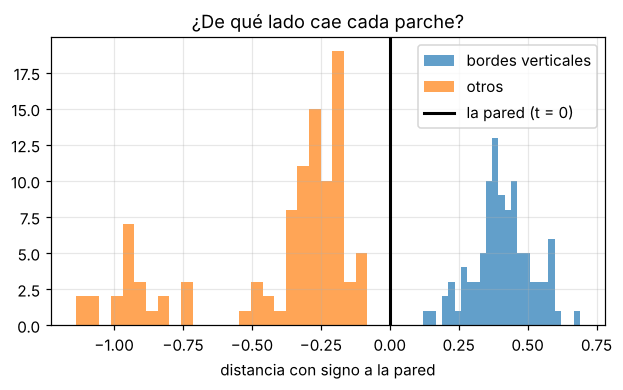

borde nítido      -> 1
pared blanca      -> 0
borde horizontal  -> 0
borde invertido   -> 0


In [61]:
t = s / np.linalg.norm(w)                         # distancia con signo, (200,)
prediccion = (s >= 0).astype(int)                 # activación escalón
exactitud = np.mean(prediccion == es_borde)
print("distancia de la pared al origen |b|/||w|| =", abs(b) / np.linalg.norm(w))
print("exactitud:", exactitud, f"({np.sum(prediccion != es_borde)} errores de {N})")

plt.figure(figsize=(6.5, 3.4))
plt.hist(t[es_borde == 1], bins=25, alpha=0.7, label="bordes verticales")
plt.hist(t[es_borde == 0], bins=25, alpha=0.7, label="otros")
plt.axvline(0, color="k", lw=2, label="la pared (t = 0)")
plt.xlabel("distancia con signo a la pared"); plt.legend(); plt.title("¿De qué lado cae cada parche?")
plt.show()

def detector_de_bordes(parche_2x2):
    # La neurona completa: aplanar -> coordenadas homogéneas -> producto punto -> escalón
    x_aug = np.append(parche_2x2.flatten(), 1.0)
    return int(w_aug @ x_aug >= 0)

for nombre, prueba in [("borde nítido", np.array([[0.0, 1.0], [0.1, 0.9]])),
                       ("pared blanca", np.full((2, 2), 0.95)),
                       ("borde horizontal", np.array([[0.0, 0.0], [1.0, 1.0]])),
                       ("borde invertido", np.array([[1.0, 0.0], [0.9, 0.1]]))]:
    print(f"{nombre:<17} -> {detector_de_bordes(prueba)}")

### 🔎 Lo que acabas de ver

| Concepto | Su papel en el detector |
|---|---|
| 1 · Vectores | Un parche es un punto de $\mathbb{R}^4$ |
| 2 · Combinación lineal | Todo parche es una mezcla de 4 patrones |
| 3 · Base | Esa mezcla existe y es única |
| 4 · Producto punto | La neurona compara cada parche con su plantilla $V$ |
| 5 · Ortogonalidad | Los coeficientes son simples proyecciones |
| 6 · Matrices | Una capa de 4 detectores es la matriz $M$ |
| 7 · Producto y composición | Todo el lote en un producto; la capa se deshace con $\frac{1}{4}M^\top$ |
| 8 · Núcleo | El detector es ciego a la iluminación y a los bordes horizontales |
| 9 · Afines | El umbral es un sesgo, es decir, un peso más |
| 10 · Hiperplano | Decidir es ver de qué lado de una pared en $\mathbb{R}^4$ cae el parche |

> 🟧 **Conexión empírica.** Los patrones $C,V,H,D$ son la base de Haar de $2\times2$. Detectores muy parecidos aparecen solos en la primera capa de las redes convolucionales entrenadas con imágenes reales.

---
# 🏆 Proyecto: construye y entrena una neurona solo con álgebra lineal

> 🎯 **Objetivo.** Construir, paso a paso, una neurona que clasifique piezas de una línea de producción como **buenas** o **defectuosas**, y **entrenarla sin descenso de gradiente**: encontrando sus pesos y su sesgo con **una proyección** (mínimos cuadrados). Al final la convertirás en una capa y verás por qué la activación es indispensable.

## 📖 La historia

Un brazo robótico revisa piezas metálicas. Una cámara mide dos cosas de cada pieza: $x_1$, la **uniformidad del color**, y $x_2$, la **rugosidad** de la superficie. Tenemos 120 piezas ya revisadas por una persona: 60 buenas ($y=+1$) y 60 defectuosas ($y=-1$). Queremos una neurona que haga el trabajo sola.

**La idea central del entrenamiento.** Buscamos pesos $w\in\mathbb{R}^2$ y un sesgo $b\in\mathbb{R}$ tales que, para cada pieza $i$,

$$w^\top x^{(i)}+b\approx y_i .$$

Con coordenadas homogéneas (concepto 9) eso se escribe para las 120 piezas a la vez como $\tilde X\tilde w\approx y$, con $\tilde X\in\mathbb{R}^{120\times3}$ y $\tilde w=(w_1,w_2,b)\in\mathbb{R}^3$. Pero $\tilde X\tilde w$ solo puede tomar valores **en el span de las columnas de $\tilde X$** (concepto 2), un subespacio de dimensión $3$ dentro de $\mathbb{R}^{120}$. Casi seguro $y$ no está ahí. Lo mejor posible es **el punto de ese subespacio más cercano a $y$: su proyección** (concepto 5). Entrenar es proyectar.

| Paso | Qué haces | Conceptos |
|---|---|---|
| P1 | Armar la matriz de datos y las etiquetas | 1 |
| P2 | Agregar la columna de unos (el sesgo) | 9 |
| P3 | Comprobar que las columnas son independientes | 3, 8 |
| P4 | Resolver las ecuaciones normales: **entrenar** | 5, 7 |
| P5 | Verificar que es una proyección | 5 |
| P6 | Ver la predicción como mezcla de columnas | 2 |
| P7 | Leer la geometría: normal, sesgo, distancias | 4, 10 |
| P8 | Clasificar y medir la exactitud | 10 |
| P9 | La dirección invisible de tu neurona | 8 |
| P10 | De neurona a capa, y el colapso sin activación | 6, 7 |
| P11 | La neurona final, como una función | todos |

> ⚠️ Los pasos son **secuenciales**: cada uno usa las variables del anterior. Si reinicias el *kernel*, vuelve a ejecutar desde P1.

#### ✏️ Ejercicio P1 · Matriz de datos

**P1 · Los datos (concepto 1).** Ya están generadas las dos nubes. Apílalas en una matriz $X\in\mathbb{R}^{120\times2}$ (primero las defectuosas, luego las buenas) y crea las etiquetas $y\in\mathbb{R}^{120}$: $-1$ para las 60 defectuosas y $+1$ para las 60 buenas.

> ✅ **Resultado esperado:** Formas `(120, 2)` y `(120,)`, y tres ✅.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
rng = np.random.default_rng(7)
n = 60
X_def = rng.normal(loc=[1.5, 3.0], scale=0.6, size=(n, 2))     # defectuosas (y = -1)
X_ok = rng.normal(loc=[3.5, 1.5], scale=0.6, size=(n, 2))      # buenas (y = +1)

X = ___
y = ___

print("X.shape =", X.shape, "| y.shape =", y.shape)
verificar("X tiene forma (120, 2)", X.shape == (120, 2))
verificar("y tiene forma (120,)", y.shape == (120,))
verificar("60 etiquetas -1 seguidas de 60 etiquetas +1", np.array_equal(y[:60], -np.ones(60)) and np.array_equal(y[60:], np.ones(60)))

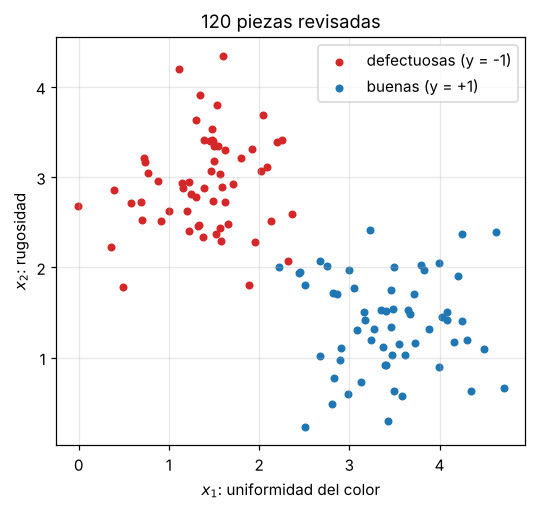

In [63]:
fig, ax = plt.subplots(figsize=(5.5, 5))
ax.scatter(*X[y == -1].T, s=18, c="tab:red", label="defectuosas (y = -1)")
ax.scatter(*X[y == 1].T, s=18, c="tab:blue", label="buenas (y = +1)")
ax.set_xlabel("$x_1$: uniformidad del color"); ax.set_ylabel("$x_2$: rugosidad")
ax.set_aspect("equal"); ax.legend(); ax.set_title("120 piezas revisadas")
plt.show()

#### ✏️ Ejercicio P2 · Coordenadas homogéneas

**P2 · El sesgo como una columna de unos (concepto 9).** Construye $\tilde X=[\,X\mid\mathbf 1\,]\in\mathbb{R}^{120\times3}$. La tercera columna es la "entrada ficticia" conectada al sesgo.

> ✅ **Resultado esperado:** Forma `(120, 3)`.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
X_aug = ___

print("X_aug.shape =", X_aug.shape)
print("primeras 3 filas:\n", X_aug[:3])
verificar("X_aug tiene forma (120, 3)", X_aug.shape == (120, 3))
verificar("la última columna es de unos", np.allclose(X_aug[:, 2], 1))
verificar("las dos primeras columnas son X", np.allclose(X_aug[:, :2], X))

#### ✏️ Ejercicio P3 · Independencia de las columnas

**P3 · ¿Hay solución única? (conceptos 3 y 8).** Por el concepto 5, $\tilde X^\top\tilde X$ es invertible si y solo si las columnas de $\tilde X$ son independientes, es decir, si el rango es $3$. Compruébalo, y comprueba también que el núcleo de $\tilde X$ es solo el $\{0\}$ (rango–nulidad: $3-\text{rango}=0$).

> ✅ **Resultado esperado:** Rango $3$ y nulidad $0$.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
rango = ___
nulidad = ___

print("rango =", rango, "| nulidad =", nulidad)
verificar("las 3 columnas son independientes", rango == 3)
verificar("el núcleo es {0}: los pesos serán únicos", nulidad == 0)

### 📐 Antes de P4: qué significan las ecuaciones normales aquí

Queremos $\tilde w\in\mathbb{R}^3$ que minimice el error cuadrático

$$E(\tilde w)=\lVert\tilde X\tilde w-y\rVert^2=\sum_{i=1}^{120}\big(w^\top x^{(i)}+b-y_i\big)^2 .$$

Por el teorema de la proyección (concepto 5), el mínimo se alcanza cuando el resto $r=y-\tilde X\tilde w$ es perpendicular a las tres columnas de $\tilde X$, lo que da las **ecuaciones normales**

$$\underbrace{\tilde X^\top\tilde X}_{G\,\in\,\mathbb{R}^{3\times3}}\ \tilde w=\underbrace{\tilde X^\top y}_{h\,\in\,\mathbb{R}^{3}} .$$

Fíjate en que $G$ es la **matriz de Gram** de las columnas de $\tilde X$: su entrada $(j,k)$ es el producto punto de la columna $j$ con la columna $k$ (concepto 4). Y la última entrada de $h$ es $\mathbf 1^\top y=\sum_iy_i$.

> 🟦 **Teorema:** la solución minimiza $E$ (concepto 5).
> 🟨 **Heurística:** usar ese mínimo para **clasificar** es una heurística. Funciona bien si las clases están separadas y no hay valores atípicos, pero también "castiga" a los puntos que están muy del lado correcto (su $s$ se aleja de $\pm1$). Es la idea de la neurona **ADALINE** (Widrow y Hoff, 1960). Hoy, para clasificar, lo estándar es la pérdida de entropía cruzada que entrenamos con gradiente en el cuaderno anterior.

#### ✏️ Ejercicio P4 · El entrenamiento en una línea

**P4 · Entrenar = resolver las ecuaciones normales (conceptos 5 y 7).** Calcula $G=\tilde X^\top\tilde X$, $h=\tilde X^\top y$ y resuelve $G\tilde w=h$. Luego separa $w=(\tilde w_1,\tilde w_2)$ y $b=\tilde w_3$.

> ✅ **Resultado esperado:** Cuatro ✅. Deberías obtener $w_1>0$ y $w_2<0$: piezas uniformes y lisas tienden a ser buenas.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
G = ___
h = ___
w_aug = ___

w = w_aug[:2]
b = w_aug[2]

print("G =\n", G, "\nh =", h)
print("w =", w, "| b =", b)
verificar("G tiene forma (3, 3) y h forma (3,)", G.shape == (3, 3) and h.shape == (3,))
verificar("G es simétrica (es una matriz de Gram)", np.allclose(G, G.T))
verificar("la entrada (3,3) de G es N = 120", np.isclose(G[2, 2], 120))
verificar("w_aug resuelve las ecuaciones normales", np.allclose(G @ w_aug, h))

#### ✏️ Ejercicio P5 · Verificar la proyección

**P5 · ¿Es de verdad una proyección? (concepto 5).** Calcula las predicciones $\hat y=\tilde X\tilde w$ y el resto $r=y-\hat y$. Comprueba que $r$ es perpendicular a las tres columnas ($\tilde X^\top r\approx0$), que se cumple Pitágoras ($\lVert y\rVert^2=\lVert\hat y\rVert^2+\lVert r\rVert^2$) y que `np.linalg.lstsq` da los mismos pesos.

> ✅ **Resultado esperado:** Tres ✅: $\hat y$ es la proyección de $y$ sobre el span de las columnas.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
y_hat = ___
r = ___

w_lib, *_ = np.linalg.lstsq(X_aug, y, rcond=None)
print("X_aug^T r =", X_aug.T @ r)
print("||y||² =", y @ y, "| ||y_hat||² + ||r||² =", y_hat @ y_hat + r @ r)
print("w_aug (ecuaciones normales):", w_aug, "| lstsq:", w_lib)
verificar("el resto es perpendicular a las columnas", np.allclose(X_aug.T @ r, 0, atol=1e-8))
verificar("Pitágoras: ||y||² = ||y_hat||² + ||r||²", np.isclose(y @ y, y_hat @ y_hat + r @ r))
verificar("coincide con np.linalg.lstsq", np.allclose(w_aug, w_lib))

#### ✏️ Ejercicio P6 · La lectura por columnas

**P6 · Las 120 respuestas son una mezcla de 3 columnas (concepto 2).** Por la lectura por columnas, $\hat y=w_1\,(\text{columna }1)+w_2\,(\text{columna }2)+b\,\mathbf 1$. Escríbelo explícitamente con las columnas de $X$ y compáralo con $\hat y$.

> ✅ **Resultado esperado:** Un ✅. El vector $\hat y\in\mathbb{R}^{120}$ vive en un subespacio de dimensión $3$.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
mezcla = ___

print("primeras 5 de y_hat :", y_hat[:5])
print("primeras 5 de mezcla:", mezcla[:5])
verificar("y_hat es exactamente esa combinación de columnas", np.allclose(mezcla, y_hat))

#### ✏️ Ejercicio P7 · Normal, sesgo y distancias

**P7 · Leer la geometría de tu neurona (conceptos 4 y 10).** Calcula $\lVert w\rVert$, la normal unitaria $\hat w$, la distancia de la pared al origen y la **distancia con signo** de las 120 piezas a la pared, con una sola expresión.

> ✅ **Resultado esperado:** Cuatro ✅. La normal $\hat w$ apunta desde la nube de defectuosas hacia la de buenas.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
norma_w = ___
w_hat = ___
dist_origen = ___
t = ___

print("||w|| =", norma_w, "| w_hat =", w_hat, "| distancia al origen =", dist_origen)
print("distancia media (con signo) de las defectuosas:", t[y == -1].mean())
print("distancia media (con signo) de las buenas     :", t[y == 1].mean())
verificar("w_hat es unitario", np.isclose(np.linalg.norm(w_hat), 1))
verificar("t tiene forma (120,)", t.shape == (120,))
verificar("las defectuosas quedan, en promedio, del lado negativo", t[y == -1].mean() < 0)
verificar("las buenas quedan, en promedio, del lado positivo", t[y == 1].mean() > 0)

#### ✏️ Ejercicio P8 · La decisión

**P8 · Clasificar (concepto 10).** La decisión es el lado de la pared: `np.sign(X @ w + b)`. Calcula las predicciones y la exactitud (la fracción de aciertos).

> ✅ **Resultado esperado:** Exactitud de al menos $0.95$.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
prediccion = ___
exactitud = ___

print("exactitud =", exactitud, f"({int(np.sum(prediccion != y))} errores de {len(y)})")
verificar("prediccion tiene forma (120,)", prediccion.shape == (120,))
verificar("la neurona acierta al menos el 95%", exactitud >= 0.95)

Dibujamos la pared que aprendió tu neurona, su normal y la región de cada clase. *(Esta celda no tiene espacios: solo ejecútala.)*

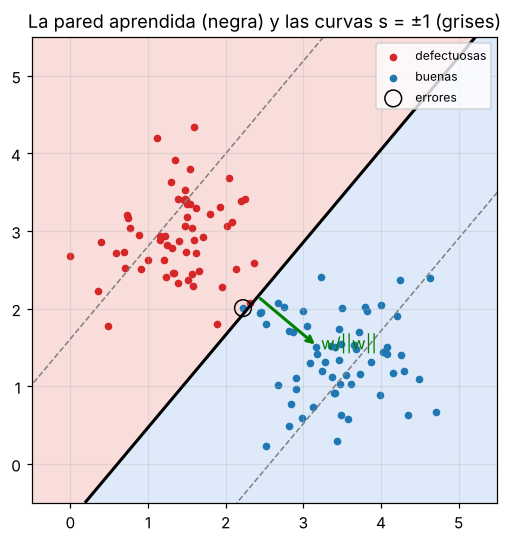

In [71]:
g1 = np.linspace(-0.5, 5.5, 300)
g2 = np.linspace(-0.5, 5.5, 300)
G1, G2 = np.meshgrid(g1, g2)
S = w[0] * G1 + w[1] * G2 + b

fig, ax = plt.subplots(figsize=(6, 5.5))
ax.contourf(G1, G2, np.sign(S), levels=[-2, 0, 2], colors=["#f4c7c3", "#c9dcf5"], alpha=0.6)
ax.contour(G1, G2, S, levels=[-1, 1], colors="gray", linestyles="--", linewidths=1)
ax.contour(G1, G2, S, levels=[0], colors="k", linewidths=2)
ax.scatter(*X[y == -1].T, s=16, c="tab:red", label="defectuosas")
ax.scatter(*X[y == 1].T, s=16, c="tab:blue", label="buenas")
errores = prediccion != y
ax.scatter(*X[errores].T, s=120, facecolors="none", edgecolors="k", label="errores")
m = X.mean(axis=0)                             # centro de todos los datos
pie = m - ((w @ m + b) / np.linalg.norm(w)) * w_hat     # su punto más cercano en la pared (concepto 10)
flecha(ax, w_hat, origen=pie, color="green", texto="w/||w||")
ax.set_xlim(-0.5, 5.5); ax.set_ylim(-0.5, 5.5); ax.set_aspect("equal"); ax.legend(loc="upper right", fontsize=8)
ax.set_title("La pared aprendida (negra) y las curvas s = ±1 (grises)")
plt.show()

#### ✏️ Ejercicio P9 · Lo que tu neurona no ve

**P9 · La dirección invisible (concepto 8).** Tu neurona vive en $\mathbb{R}^2$, así que su núcleo tiene dimensión $2-1=1$: una recta, perpendicular a $w$. Construye un vector $d$ de esa recta con la receta $d=(-w_2,\ w_1)$ y comprueba que mover una pieza a lo largo de $d$ **no cambia** la respuesta de la neurona. Interpreta: ¿qué combinación de "uniformidad" y "rugosidad" le es indiferente?

> ✅ **Resultado esperado:** La respuesta no cambia. Moverse a lo largo de $d$ es moverse **paralelo a la pared**.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
d = ___

pieza = X[0]
print("d =", d, "| w·d =", w @ d)
for paso in (0.0, 1.0, -2.5):
    print(f"pieza + {paso:>4} d -> respuesta s = {w @ (pieza + paso * d) + b:.6f}")
verificar("d está en el núcleo de la neurona", np.isclose(w @ d, 0))
verificar("moverse a lo largo de d no cambia la respuesta", np.isclose(w @ (pieza + 3 * d) + b, w @ pieza + b))

### 📐 Antes de P10: de neurona a capa, y por qué hace falta la activación

Supón que agregamos una segunda neurona ya diseñada, $\tilde w_2=(1,\ 1,\ -4)$, que responde a piezas con medidas altas ($x_1+x_2>4$). Juntas forman una capa $\tilde W\in\mathbb{R}^{2\times3}$, cuyas filas son $\tilde w^\top$ y $\tilde w_2^\top$ (concepto 6). Para todo el lote, sus salidas son $\tilde X\tilde W^\top\in\mathbb{R}^{120\times2}$ (concepto 7).

Ahora una tercera neurona combina esas dos salidas con pesos $v\in\mathbb{R}^2$. **Sin activación en medio**:

$$\big(\tilde X\tilde W^\top\big)\,v=\tilde X\,\big(\tilde W^\top v\big)=\tilde X\,\tilde w_{\text{eq}},\qquad \tilde w_{\text{eq}}=\tilde W^\top v\in\mathbb{R}^3 .$$

Las tres neuronas equivalen a **una sola neurona**, con una sola pared. **Con una activación** (por ejemplo el signo) entre la capa y la tercera neurona, la igualdad se rompe, y la red ya puede dibujar fronteras que no son una sola recta.

#### ✏️ Ejercicio P10 · Capa, colapso y activación

**P10 · De neurona a capa (conceptos 6 y 7).** Arma $\tilde W$ apilando como filas tu $\tilde w$ y $\tilde w_2$. Calcula la salida de la capa para el lote, la neurona equivalente $\tilde w_{\text{eq}}=\tilde W^\top v$ con $v=(1,1)$, y comprueba el colapso. Al final, comprueba que **con** la activación signo en medio ya **no** colapsa.

> ✅ **Resultado esperado:** Cuatro ✅.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
w2_aug = np.array([1.0, 1.0, -4.0])
v = np.array([1.0, 1.0])

W_aug = ___
salida_capa = ___
w_eq = ___

dos_niveles = salida_capa @ v
una_neurona = X_aug @ w_eq
con_activacion = np.sign(salida_capa) @ v

print("W_aug:", W_aug.shape, "| salida de la capa:", salida_capa.shape, "| w_eq:", w_eq)
verificar("W_aug tiene forma (2, 3)", W_aug.shape == (2, 3))
verificar("la capa da forma (120, 2)", salida_capa.shape == (120, 2))
verificar("sin activación, las tres neuronas son UNA sola", np.allclose(dos_niveles, una_neurona))
verificar("con activación ya no colapsan", not np.allclose(con_activacion, una_neurona))

#### ✏️ Ejercicio P11 · La neurona como función

**P11 · Tu neurona, terminada.** Escribe la función `mi_neurona(X_nuevo)`: recibe piezas como filas, agrega la columna de unos, hace el producto con $\tilde w$ y aplica la activación signo. Pruébala con piezas nuevas.

> ✅ **Resultado esperado:** `[ 1 -1  1 -1]`.

In [ ]:
# ✏️ Rellena los ___ y ejecuta
def mi_neurona(X_nuevo):
    X_nuevo = np.atleast_2d(X_nuevo)                       # admite una pieza o un lote
    X_nuevo_aug = ___
    s = ___
    return np.where(s >= 0, 1, -1)

piezas_nuevas = np.array([[3.6, 1.4],      # parecida a las buenas
                          [1.4, 3.1],      # parecida a las defectuosas
                          [4.2, 0.8],
                          [0.9, 3.8]])
print("decisiones:", mi_neurona(piezas_nuevas))
print("una sola pieza:", mi_neurona(np.array([3.0, 1.0])))
verificar("clasifica bien las 4 piezas nuevas", np.array_equal(mi_neurona(piezas_nuevas), [1, -1, 1, -1]))
verificar("da lo mismo que la clasificación del paso P8 en los datos", np.array_equal(mi_neurona(X), np.where(X @ w + b >= 0, 1, -1)))

### ✍️ Para escribir con tus propias palabras

En una celda de texto (o en tu Obsidian), responde:

1. **Entrenar es proyectar.** Explica por qué $\hat y=\tilde X\tilde w$ tenía que estar en un subespacio de dimensión $3$ de $\mathbb{R}^{120}$, y por qué la "mejor" neurona es la proyección de $y$ sobre él.
2. **El sesgo.** ¿Qué habría pasado si no hubieras agregado la columna de unos? (Pista: ¿por dónde tendría que pasar la pared? Mira dónde están las dos nubes.)
3. **La ceguera.** En P9, ¿qué tipo de pieza "le da igual" a tu neurona? ¿Es eso razonable para este problema?
4. **El colapso.** Usando P10, explica por qué una red sin activaciones, por grande que sea, no puede separar datos que necesiten más de una pared.

## 🧭 Comparación con el cuaderno anterior

| | Cuaderno `neurona-10-conceptos` | Este proyecto |
|---|---|---|
| Etiquetas | $y\in\{0,1\}$ | $y\in\{-1,+1\}$ |
| Salida | sigmoide $\sigma(w^\top x+b)$ | signo de $w^\top x+b$ |
| Pérdida | entropía cruzada binaria | error cuadrático $\lVert\tilde X\tilde w-y\rVert^2$ |
| Entrenamiento | descenso de gradiente (iterativo) | **una proyección** (ecuaciones normales, exacto) |
| Estatus para clasificar | 🟧 estándar en la práctica | 🟨 heurística clásica (ADALINE) |

Las dos neuronas tienen **la misma forma**, $f(w^\top x+b)$, y por tanto la misma geometría: una pared en el espacio de entrada. Lo que cambia es **cómo se elige** la pared.

---
# 🎓 Cierre

## La neurona, pieza por pieza

$$z=f\big(\underbrace{w^\top x}_{\text{conceptos }4,\,5,\,8}+\underbrace{b}_{\text{concepto }9}\big),\qquad x,w\in\mathbb{R}^n\ \text{(concepto 1)},$$

$$\text{frontera: }\{x:\ w^\top x+b=0\}\ \text{(concepto 10)},\qquad \text{capa: }y=Wx+b\ \text{(conceptos 2, 6, 7)},\qquad \text{entradas redundantes: concepto 3}.$$

## Lo que debes llevarte

1. Los datos son **puntos de $\mathbb{R}^n$**, y el `shape` es lo primero que se revisa.
2. $w^\top x$ **compara** la entrada con el patrón $w$; por Cauchy–Schwarz, la respuesta es máxima cuando se parecen.
3. Una neurona es **ciega a $n-1$ direcciones**: solo ve la sombra de $x$ sobre $w$.
4. El sesgo es **un peso más** (coordenadas homogéneas), y con él la frontera es un **hiperplano afín**.
5. $\dfrac{w^\top x+b}{\lVert w\rVert}$ es la **distancia con signo** a esa frontera.
6. Una capa es **una matriz**; un lote, **un producto de matrices** $XW^\top$.
7. Sin activación, **las capas colapsan** en una sola transformación afín.
8. Una neurona lineal se puede **entrenar proyectando** las etiquetas sobre el span de las columnas de los datos.

## Estatus de lo que afirmamos

| Afirmación | Tipo |
|---|---|
| $\mathbb{R}^n$ es espacio vectorial | 🟦 Teorema |
| $Ax$ es combinación de las columnas de $A$ | 🟦 Teorema |
| Coordenadas en una base son únicas | 🟦 Teorema |
| Todas las bases tienen el mismo tamaño | 🟦 Teorema (citado) |
| Cauchy–Schwarz | 🟦 Teorema |
| Proyección = punto más cercano; ecuaciones normales | 🟦 Teorema |
| Toda transformación lineal es una matriz | 🟦 Teorema |
| $B(Ax)=(BA)x$, $(AB)^\top=B^\top A^\top$ | 🟦 Teorema |
| Rango–nulidad | 🟦 Teorema (citado) |
| Composición de afines es afín | 🟦 Teorema |
| Distancia con signo a un hiperplano | 🟦 Teorema |
| Descenso de gradiente desde $w=0$ deja $w$ en el span de los datos | 🟦 Teorema (inducción, concepto 2) |
| Ecuaciones normales empeoran el condicionamiento | 🟦 Resultado de análisis numérico |
| Mínimos cuadrados para clasificar (ADALINE) | 🟨 Heurística |
| Umbral elegido a mano en el ejemplo unificador | 🟨 Heurística |
| Filtros tipo borde en la primera capa de una CNN | 🟧 Práctica empírica (observación) |

## ➡️ Lo que sigue

- **Capas con activación**: varias paredes combinadas para resolver problemas que una sola no puede (como XOR).
- **Convoluciones**: la misma neurona del ejemplo unificador, deslizada por toda una imagen.
- **Descomposiciones** (autovalores, SVD): para entender qué direcciones "importan" en los datos y en los pesos. Ya la usaste sin verla: `null_space` y `matrix_rank` se calculan con la SVD.